# LAB 06 - Attention Mechanism

Từ recurrent state sang context-aware representation. Notebook gồm:

1. Kiểm tra các bài tính tay bằng `attention_numpy.py` (scores, softmax, context, scaling, numerical stability, self-attention).
2. Experiment 1 - 2: attention distribution trên một câu với query giả lập, và khi đổi query.
3. Scaling và temperature.
4. Train ba sentiment classifier trên IMDb (cùng split, vocabulary, max_length = 200 như LAB 05): LSTM, Self-Attention, Self-Attention + positional embedding.
5. Experiment 3: attention visualization (`attention_heatmap.png`).
6. Experiment 4: RNN context vs attention context.
7. Experiment 5: sequence length và computational cost.
8. Evaluation (`confusion_matrix.png`), application, error analysis.

Load dữ liệu, làm sạch và split dùng lại `lab4/preprocessing.py`. Self-attention trong PyTorch được viết tay theo đúng công thức của `attention_numpy.py` (không dùng `nn.MultiheadAttention`). Notebook ghi `results.csv` và các hình `.png`.

## 0. Setup

In [1]:
import math
import os
import sys
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.pipeline import Pipeline

sys.path.insert(0, os.path.abspath("../lab4"))
from preprocessing import (LABEL_NAMES, clean_text, deduplicate, load_imdb, preprocess,
                           remove_overlap, split_train_val, tokenize)
from attention_numpy import (SELF_ATTN_EXAMPLE, entropy, scaled_dot_product_attention,
                             self_attention, softmax, softmax_naive)

SEED = 42
QUICK = os.environ.get("LAB6_QUICK") == "1"   # chạy thử nhanh trên tập con, không dùng cho kết quả nộp
torch.set_num_threads(8)
pd.set_option("display.max_colwidth", 200)

# Cấu hình giống LAB 05 để so sánh được
MAX_VOCAB = 20000
EMBED_DIM = 100
HIDDEN = 128             # hidden size của LSTM = d_k của self-attention
DROPOUT = 0.3
BATCH = 64
LR = 1e-3
EPOCHS = 2 if QUICK else 8
CLIP = 1.0
MAX_LEN = 200
PAD, UNK = 0, 1

RESULTS = []
def log(experiment, model, setting, split, metric, value):
    RESULTS.append({"experiment": experiment, "model": model, "setting": setting,
                    "split": split, "metric": metric, "value": value})

def metrics(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}

print("torch", torch.__version__, "| CPU threads:", torch.get_num_threads(), "| QUICK =", QUICK)

torch 2.13.0+cpu | CPU threads: 8 | QUICK = False


## 1. Kiểm tra các bài tính tay

Chi tiết từng bước ở `calculations.md`. Ở đây chỉ chạy lại bằng `attention_numpy.py` để đối chiếu.

In [2]:
q = np.array([1, 2]); K1 = np.array([[1, 0], [0, 1], [1, 1]])
print("Bài 1: s = K q =", K1 @ q)
a2 = softmax([1, 2, 3])
print("Bài 2: softmax([1,2,3]) =", a2.round(4), " tổng =", a2.sum())
print("Bài 3: c =", np.array([0.1, 0.2, 0.7]) @ np.array([[1, 0], [0, 1], [2, 2]]))
s4, w4, c4 = scaled_dot_product_attention([[1, 0]], [[1, 0], [0, 1], [1, 1]], [[1, 0], [0, 2], [2, 1]], scale=False)
print("Bài 4: scores =", s4[0], " weights =", w4[0].round(4), " context =", c4[0].round(4))
print("Scaling d_k = 4: không scale", softmax([4, 2, 0]).round(4), "| scale", softmax(np.array([4, 2, 0]) / 2).round(4))
log("calc", "-", "bai2", "-", "alpha", str(a2.round(4).tolist()))
log("calc", "-", "bai4", "-", "context", str(c4[0].round(4).tolist()))

Bài 1: s = K q = [1 2 3]
Bài 2: softmax([1,2,3]) = [0.09   0.2447 0.6652]  tổng = 0.9999999999999999
Bài 3: c = [1.5 1.6]
Bài 4: scores = [1. 0. 1.]  weights = [0.4223 0.1554 0.4223]  context = [1.267 0.733]
Scaling d_k = 4: không scale [0.8668 0.1173 0.0159] | scale [0.6652 0.2447 0.09  ]


### Numerical stability

softmax tính trực tiếp với x = [1000, 1001, 1002] bị tràn số (e^1000 > 1.8·10^308). Bản ổn định trừ max(x) trước, cho kết quả giống softmax([1, 2, 3]). Với score rất âm, tính trực tiếp bị underflow (0/0).

In [3]:
for x in [[1, 2, 3], [1000, 1001, 1002], [-1000, -1001, -1002]]:
    print(f"x = {x}: naive = {softmax_naive(x)}, stable = {softmax(x).round(4)}")
print("softmax([1,1,1,1]) =", softmax([1, 1, 1, 1]), "| softmax([1,1,10]) =", softmax([1, 1, 10]).round(6))
log("stability", "-", "[1000,1001,1002]", "-", "naive", str(softmax_naive([1000, 1001, 1002]).tolist()))
log("stability", "-", "[1000,1001,1002]", "-", "stable", str(softmax([1000, 1001, 1002]).round(4).tolist()))

x = [1, 2, 3]: naive = [0.09003057 0.24472847 0.66524096], stable = [0.09   0.2447 0.6652]
x = [1000, 1001, 1002]: naive = [nan nan nan], stable = [0.09   0.2447 0.6652]
x = [-1000, -1001, -1002]: naive = [nan nan nan], stable = [0.6652 0.2447 0.09  ]
softmax([1,1,1,1]) = [0.25 0.25 0.25 0.25] | softmax([1,1,10]) = [1.23000e-04 1.23000e-04 9.99753e-01]


### Self-attention: ["I", "like", "cats"]

X, W_Q, W_K, W_V là ma trận giả định (đề không cho số cụ thể), giống `calculations.md`.

In [4]:
ex = SELF_ATTN_EXAMPLE
out = self_attention(ex["X"], ex["W_Q"], ex["W_K"], ex["W_V"])
toks3 = ex["tokens"]
for k in ["Q", "K", "V"]:
    print(k, "=", out[k].tolist())
print("QK^T =", (out["Q"] @ out["K"].T).tolist())
display(pd.DataFrame(out["weights"], index=toks3, columns=toks3).round(4).rename_axis("query \\ key"))
display(pd.DataFrame(out["context"], index=toks3, columns=["dim 1", "dim 2"]).round(4))
for i, t in enumerate(toks3):
    for j, u in enumerate(toks3):
        log("calc_self_attention", "-", f"{t}->{u}", "-", "weight", out["weights"][i, j])

Q = [[1.0, 0.0], [1.0, 1.0], [2.0, 1.0]]
K = [[1.0, 1.0], [0.0, 1.0], [1.0, 2.0]]
V = [[1.0, 0.0], [0.0, 2.0], [1.0, 2.0]]
QK^T = [[1.0, 0.0, 1.0], [2.0, 1.0, 3.0], [3.0, 1.0, 4.0]]


,I,like,cats
query \ key,,,
I,0.4011,0.1978,0.4011
like,0.2840,0.1400,0.5760
cats,0.3057,0.0743,0.6200


,dim 1,dim 2
I,0.8022,1.1978
like,0.8600,1.4320
cats,0.9257,1.3886


## 2. Dữ liệu và Word2Vec

Split giống LAB 04 - 05. Word2Vec (Skip-gram, d = 100, window 5, min_count 5, 10 epoch) train trên TRAIN, dùng làm embedding cố định cho Experiment 1 - 3.

In [5]:
train_raw, test_raw = load_imdb()
train_full = deduplicate(train_raw)
test_df = remove_overlap(deduplicate(test_raw), train_full)
train_df, val_df = split_train_val(train_full, val_size=0.2, seed=SEED)
if QUICK:
    train_df = train_df.sample(3000, random_state=SEED).reset_index(drop=True)
    val_df = val_df.sample(500, random_state=SEED).reset_index(drop=True)
    test_df = test_df.sample(1000, random_state=SEED).reset_index(drop=True)
X_train, y_train = train_df["text"].tolist(), train_df["label"].values
X_val, y_val = val_df["text"].tolist(), val_df["label"].values
X_test, y_test = test_df["text"].tolist(), test_df["label"].values
tok_train = [preprocess(t) for t in X_train]
tok_val = [preprocess(t) for t in X_val]
tok_test = [preprocess(t) for t in X_test]
print("train / validation / test:", len(train_df), len(val_df), len(test_df))

from gensim.models import Word2Vec
t0 = time.perf_counter()
w2v = Word2Vec(tok_train, vector_size=EMBED_DIM, window=5, min_count=5, sg=1, epochs=3 if QUICK else 10,
               workers=4, seed=SEED)
wv = w2v.wv
print(f"Word2Vec: {len(wv):,} từ, {time.perf_counter() - t0:.0f} s")

def w2v_matrix(tokens):
    return np.stack([wv[w] if w in wv.key_to_index else np.zeros(EMBED_DIM, dtype=np.float32) for w in tokens])

train / validation / test: 19923 4981 24678


Word2Vec: 27,006 từ, 94 s


## 3. Experiment 1 - Attention distribution

Sequence: "The movie was surprisingly good despite a very slow beginning." Mỗi token là một key và value: K = V = embedding Word2Vec của token (10 × 100).

Query giả lập là vector trung bình của một nhóm từ mồi. Từ mồi **không trùng** với token nào trong câu, để query không "chọn sẵn" đáp án:

- Query A (sentiment): great, excellent, wonderful, terrible, awful, bad, boring, enjoyable.
- Query B (topic): film, plot, story, scene, actors, director, script, cinema.

Score: s_i = q · k_i (dot-product như mục 5 của đề), α = softmax(s), c = Σ α_i v_i. Cột "attention /√d" là softmax(s / √100) để so sánh với scaled dot-product (phân tích ở mục 4).

In [6]:
SENT = "The movie was surprisingly good despite a very slow beginning."
sent_toks = preprocess(SENT)
X_sent = w2v_matrix(sent_toks)
QUERY_WORDS = {
    "A: sentiment": ["great", "excellent", "wonderful", "terrible", "awful", "bad", "boring", "enjoyable"],
    "B: topic": ["film", "plot", "story", "scene", "actors", "director", "script", "cinema"],
}
assert not any(w in sent_toks for ws in QUERY_WORDS.values() for w in ws)
queries = {name: w2v_matrix(ws).mean(0) for name, ws in QUERY_WORDS.items()}

print(f"Word2Vec: std của mỗi thành phần = {wv.vectors.std():.3f}, ‖x‖ trung bình của câu = {np.linalg.norm(X_sent, axis=1).mean():.2f}")
exp1 = {}
for name, qv in queries.items():
    s, w, c = scaled_dot_product_attention(qv[None], X_sent, X_sent, scale=False)
    w_scaled = scaled_dot_product_attention(qv[None], X_sent, X_sent)[1][0]
    exp1[name] = {"score": s[0], "attention": w[0], "attention /√d": w_scaled, "context": c[0]}
    log("exp1_distribution", name, "all", "-", "entropy_dot", entropy(w[0]))
    log("exp1_distribution", name, "all", "-", "entropy_scaled", entropy(w_scaled))
    for t, sc, a in zip(sent_toks, s[0], w[0]):
        log("exp1_distribution", name, t, "-", "score", sc)
        log("exp1_distribution", name, t, "-", "attention", a)
    print(f"{name}: entropy = {entropy(w[0]):.3f}, chia √d: {entropy(w_scaled):.3f} (đều: {np.log(len(sent_toks)):.3f}), "
          f"context gần nhất với {[(x, round(y, 2)) for x, y in wv.similar_by_vector(c[0], topn=5)]}")

tbl = pd.DataFrame({"token": sent_toks} | {f"{n} {k}": exp1[n][k] for n in exp1 for k in ["score", "attention", "attention /√d"]})
tbl.round(4)

Word2Vec: std của mỗi thành phần = 0.237, ‖x‖ trung bình của câu = 2.50
A: sentiment: entropy = 1.940, chia √d: 2.300 (đều: 2.303), context gần nhất với [('good', 0.87), ('downsides', 0.77), ('suprise', 0.77), ('rediculous', 0.76), ('prototypical', 0.76)]
B: topic: entropy = 2.160, chia √d: 2.301 (đều: 2.303), context gần nhất với [('rewatching', 0.79), ('cq', 0.79), ('infrequent', 0.79), ('falters', 0.78), ('plotwise', 0.78)]


,token,A: sentiment score,A: sentiment attention,A: sentiment attention /√d,B: topic score,B: topic attention,B: topic attention /√d
0,the,1.7208,0.0328,0.0922,1.5692,0.0472,0.0939
1,movie,2.8292,0.0995,0.1030,3.1792,0.2362,0.1103
2,was,2.1386,0.0499,0.0961,2.0381,0.0755,0.0984
3,surprisingly,2.7861,0.0953,0.1026,2.2038,0.0891,0.1001
4,good,4.1728,0.3814,0.1178,2.1566,0.0850,0.0996
5,despite,1.6043,0.0292,0.0911,1.6195,0.0496,0.0944
6,a,1.6627,0.0310,0.0917,1.5438,0.0460,0.0937
7,very,2.6183,0.0806,0.1009,2.2332,0.0917,0.1004
8,slow,3.1796,0.1413,0.1067,2.8261,0.1659,0.1065
9,beginning,2.3074,0.0590,0.0978,2.4490,0.1138,0.1026


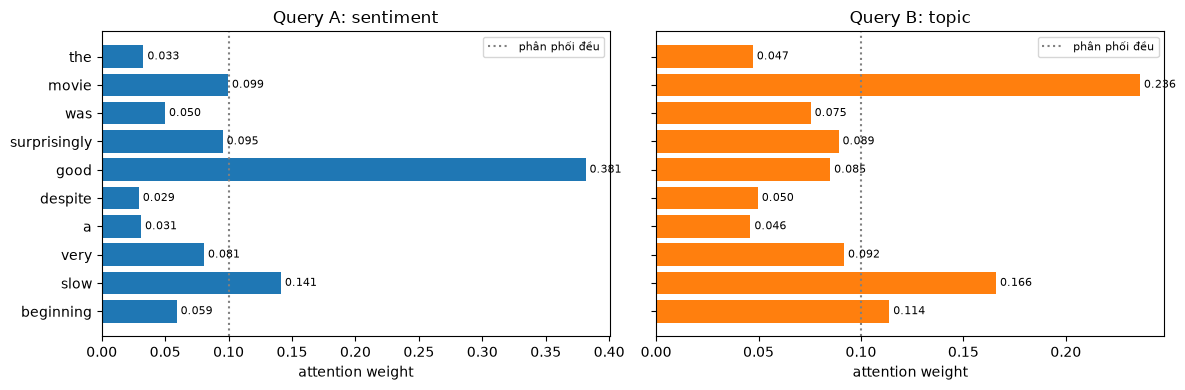

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, r) in zip(axes, exp1.items()):
    y = np.arange(len(sent_toks))[::-1]
    ax.barh(y, r["attention"], color="tab:blue" if "A" in name else "tab:orange")
    ax.axvline(1 / len(sent_toks), color="gray", ls=":", label="phân phối đều")
    ax.set_yticks(y, sent_toks)
    ax.set(title=f"Query {name}", xlabel="attention weight")
    for yi, a in zip(y, r["attention"]):
        ax.text(a, yi, f" {a:.3f}", va="center", fontsize=8)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("query_attention.png", dpi=120)
plt.show()

**Experiment 1 - phân phối attention (Query A, sentiment):** "good" nhận 0.381 (gấp 3.8 lần mức đều 0.1), tiếp theo là slow 0.141, movie 0.099, surprisingly 0.095. Các từ chức năng the, a, despite chỉ khoảng 0.03. Entropy 1.94 so với mức tối đa ln 10 = 2.303. Context vector gần nhất với từ "good" (cos 0.87), tức c chủ yếu mang thông tin của "good".

**Experiment 2 - đổi query (Query B, topic):** với **cùng keys và values**, phân phối đổi hẳn. movie tăng từ 0.099 lên 0.236 (cao nhất), beginning từ 0.059 lên 0.114, còn good giảm từ 0.381 xuống 0.085. Entropy 2.16, phẳng hơn Query A vì câu ít từ thuộc chủ đề "phim". Vậy attention không phải một danh sách "từ quan trọng nhất" cố định của câu: nó trả lời câu hỏi mà query đặt ra.

Lưu ý khi đọc kết quả:

- "slow" cao ở cả hai query (0.141 và 0.166). Dot product phụ thuộc cả độ lớn vector chứ không chỉ hướng: slow có ‖x‖ lớn nhất câu, còn the có ‖x‖ nhỏ nhất. Score cao vì vậy không chắc là "liên quan về nghĩa".
- Nếu chia √100 như scaled dot-product, cả hai phân phối gần như đều (entropy 2.300 và 2.301). Lý do: thành phần của vector Word2Vec có độ lệch chuẩn chỉ 0.237, không phải 1 như giả định của quy tắc √d_k, nên dot product vốn đã nhỏ (1.5 - 4.2); chia thêm cho 10 làm chênh lệch giữa các score dưới 0.3. Trong model học được, W_Q và W_K tự điều chỉnh độ lớn, còn ở đây query là giả lập nên dùng dot-product như mục 5 của đề.

## 4. Scaling và temperature

### Temperature

Cùng score vector của Query A, α = softmax(s / T). Entropy tính bằng nat, phân phối đều trên 10 token có entropy ln 10 = 2.303. "Số token hiệu dụng" = e^H.

In [8]:
s_A = exp1["A: sentiment"]["score"]
temp_rows = []
for T in [0.5, 1.0, 2.0]:
    p = softmax(s_A, temperature=T)
    temp_rows.append({"T": T, "max weight": p.max(), "token max": sent_toks[p.argmax()], "entropy": entropy(p),
                      "số token hiệu dụng e^H": np.exp(entropy(p)),
                      "top 3": ", ".join(f"{sent_toks[i]} {p[i]:.3f}" for i in np.argsort(-p)[:3])})
    log("temperature", "A: sentiment", f"T={T}", "-", "max_weight", p.max())
    log("temperature", "A: sentiment", f"T={T}", "-", "entropy", entropy(p))
temp_df = pd.DataFrame(temp_rows).set_index("T")
temp_df.round(4)

,max weight,token max,entropy,số token hiệu dụng e^H,top 3
T,,,,,
0.5,0.7282,good,1.0644,2.8992,"good 0.728, slow 0.100, movie 0.050"
1.0,0.3814,good,1.9404,6.9615,"good 0.381, slow 0.141, movie 0.099"
2.0,0.2132,good,2.2186,9.1942,"good 0.213, slow 0.130, movie 0.109"


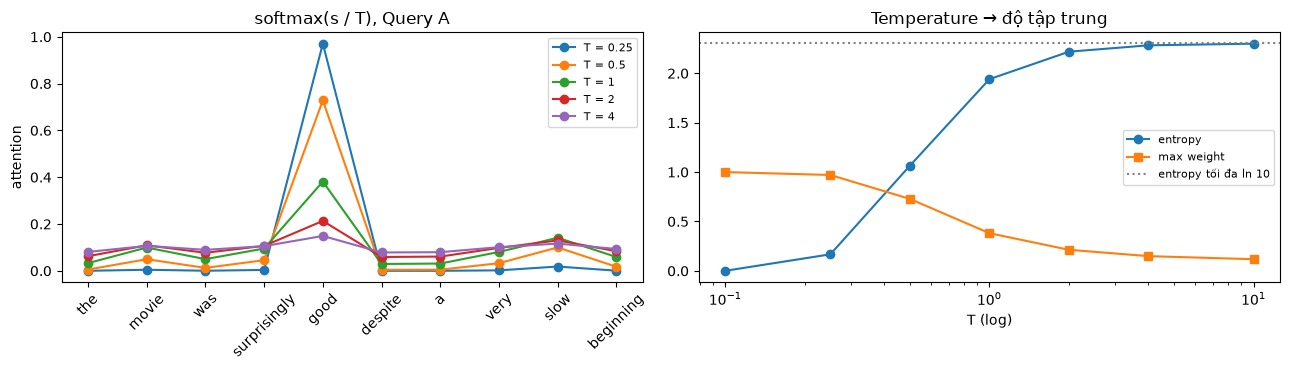

In [9]:
Ts_plot = [0.1, 0.25, 0.5, 1, 2, 4, 10]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for T in [0.25, 0.5, 1, 2, 4]:
    axes[0].plot(sent_toks, softmax(s_A, temperature=T), "o-", label=f"T = {T}")
axes[0].set(title="softmax(s / T), Query A", ylabel="attention")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8)
axes[1].semilogx(Ts_plot, [entropy(softmax(s_A, temperature=T)) for T in Ts_plot], "o-", label="entropy")
axes[1].semilogx(Ts_plot, [softmax(s_A, temperature=T).max() for T in Ts_plot], "s-", label="max weight")
axes[1].axhline(np.log(len(sent_toks)), color="gray", ls=":", label="entropy tối đa ln 10")
axes[1].set(title="Temperature → độ tập trung", xlabel="T (log)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("temperature.png", dpi=120)
plt.show()

### Vì sao chia cho √d_k

Lấy q, k_1..k_10 ngẫu nhiên, mỗi thành phần ~ N(0, 1), với d_k từ 4 tới 1024 (2,000 lần lặp). So sánh độ lệch chuẩn của score, max weight, entropy và độ lớn gradient của softmax ‖∂α/∂s‖_F = ‖diag(α) − αα^T‖_F khi có và không có scaling.

In [10]:
rng = np.random.default_rng(SEED)
scale_rows = []
for d in [4, 16, 64, 256, 1024]:
    qd = rng.normal(size=(2000, 1, d)); kd = rng.normal(size=(2000, 10, d))
    raw = (qd @ kd.transpose(0, 2, 1))[:, 0, :]
    for name, S in [("không scaling", raw), ("chia √d_k", raw / np.sqrt(d))]:
        P = softmax(S)
        jac = np.array([np.linalg.norm(np.diag(p) - np.outer(p, p)) for p in P[:500]])
        scale_rows.append({"d_k": d, "scores": name, "std(score)": S.std(), "mean max weight": P.max(1).mean(),
                           "mean entropy": entropy(P).mean(), "mean ‖∂α/∂s‖": jac.mean()})
scale_df = pd.DataFrame(scale_rows)
for _, r in scale_df.iterrows():
    for k in ["std(score)", "mean max weight", "mean entropy", "mean ‖∂α/∂s‖"]:
        log("scaling", r["scores"], f"d_k={r['d_k']}", "-", k, r[k])
scale_df.pivot(index="d_k", columns="scores").round(3)

std(score)               mean max weight               mean entropy  \
scores  chia √d_k không scaling       chia √d_k không scaling    chia √d_k   
d_k                                                                          
4           1.012         2.025           0.308         0.497        1.940   
16          1.009         4.037           0.319         0.732        1.923   
64          0.998         7.981           0.319         0.871        1.929   
256         1.003        16.044           0.317         0.927        1.926   
1024        1.001        32.019           0.323         0.966        1.919   

                     mean ‖∂α/∂s‖                
scores không scaling    chia √d_k không scaling  
d_k                                              
4              1.425        0.339         0.332  
16             0.731        0.347         0.270  
64             0.329        0.346         0.160  
256            0.176        0.347         0.094  
1024           0.083        0.348         0.046

**Temperature** (cùng score của Query A):

| T | Max weight | Entropy | Số token hiệu dụng e^H |
|---|---|---|---|
| 0.5 | 0.728 (good) | 1.064 | 2.9 |
| 1.0 | 0.381 (good) | 1.940 | 7.0 |
| 2.0 | 0.213 (good) | 2.219 | 9.2 |

T thấp làm phân phối tập trung (gần chọn một token), T cao làm phân phối phẳng (gần đều 10 token, entropy tiến tới 2.303). Thứ hạng không đổi (good > slow > movie ở mọi T): temperature chỉ đổi **độ tập trung**, không đổi **thứ tự**.

**Scaling theo d_k** (q, k ngẫu nhiên N(0, 1)):

- Không scaling: độ lệch chuẩn của score đúng bằng √d_k (2.0, 4.0, 8.0, 16.0, 32.0). Max weight trung bình tăng từ 0.50 (d_k = 4) lên 0.97 (d_k = 1024): softmax gần như one-hot.
- Gradient của softmax ‖∂α/∂s‖ giảm từ 0.33 xuống 0.046 khi d_k tăng từ 4 lên 1024, tức nhỏ hơn khoảng 7.5 lần so với bản có scaling. Softmax bão hoà thì gradient truyền về Q, K gần bằng 0 và model khó học.
- Chia √d_k: độ lệch chuẩn của score luôn khoảng 1.0, max weight khoảng 0.31 - 0.32 và gradient khoảng 0.35, **không phụ thuộc d_k**. Đây là lý do của √d_k: giữ softmax ở vùng có gradient, bất kể số chiều.

Scaling chính là temperature T = √d_k.

## 5. Sentiment classifiers: LSTM vs Self-Attention

Cùng vocabulary (20,000 từ phổ biến nhất của train + PAD + UNK), cùng max_length = 200 (giữ token đầu), embedding 100 chiều học từ đầu, batch 64, Adam lr 1e-3, 8 epoch, gradient clipping 1.0, giữ checkpoint có validation loss thấp nhất. Chỉ khác cách tạo representation của câu:

- **LSTM** (giống LAB 05): Embedding → LSTM (hidden 128) → h tại token thật cuối cùng → dropout → Linear.
- **Self-Attention**: Embedding X → Q = XW_Q, K = XW_K, V = XW_V (100 → 128, không bias) → H = softmax(QKᵀ/√128 + mask) V → attention pooling với query học được u: β = softmax(H u / √128), c = Σ β_t h_t → dropout → Linear. Mask che các vị trí PAD ở cả hai bước softmax.
- **Self-Attention + pos**: như trên, nhưng X = embedding + positional embedding học được (200 vị trí). Thêm biến thể này để kiểm tra vai trò của thông tin vị trí (positional encoding là nội dung của LAB 07).

In [11]:
counter = Counter(w for toks in tok_train for w in toks)
itos = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common(MAX_VOCAB)]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)

def encode(tokens):
    return [stoi.get(w, UNK) for w in tokens]

def pad_truncate(ids, L):
    ids = ids[:L]
    n = max(len(ids), 1)
    return ids + [PAD] * (L - len(ids)), n

def to_tensors(ids_list, L=MAX_LEN):
    pairs = [pad_truncate(x, L) for x in ids_list]
    return torch.tensor([p[0] for p in pairs]), torch.tensor([p[1] for p in pairs])

ids_train, ids_val, ids_test = ([encode(t) for t in toks] for toks in (tok_train, tok_val, tok_test))
len_test = np.array([len(x) for x in ids_test])
print("vocabulary:", VOCAB_SIZE, "| review test bị truncate:", f"{100 * (len_test > MAX_LEN).mean():.1f}%")
log("vocab", "-", "-", "-", "vocab_size", VOCAB_SIZE)

vocabulary: 20002 | review test bị truncate: 40.3%


In [12]:
class SelfAttention(nn.Module):
    """Single-head scaled dot-product self-attention, cùng công thức với attention_numpy.self_attention."""
    def __init__(self, d_model, d_k):
        super().__init__()
        self.W_Q = nn.Linear(d_model, d_k, bias=False)
        self.W_K = nn.Linear(d_model, d_k, bias=False)
        self.W_V = nn.Linear(d_model, d_k, bias=False)
        self.d_k = d_k

    def forward(self, X, key_mask):
        """X: (B, T, d_model), key_mask: (B, T), True = token thật. Trả về (H, A)."""
        Q, K, V = self.W_Q(X), self.W_K(X), self.W_V(X)
        S = Q @ K.transpose(1, 2) / math.sqrt(self.d_k)               # (B, T, T)
        S = S.masked_fill(~key_mask[:, None, :], float("-inf"))      # không attend tới PAD
        A = torch.softmax(S, dim=-1)                                  # torch.softmax cũng trừ max
        return A @ V, A


class AttnClassifier(nn.Module):
    def __init__(self, use_pos=False, max_len=MAX_LEN):
        super().__init__()
        self.emb = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=PAD)
        self.pos = nn.Embedding(max_len, EMBED_DIM) if use_pos else None
        self.attn = SelfAttention(EMBED_DIM, HIDDEN)
        self.u = nn.Parameter(torch.randn(HIDDEN) / math.sqrt(HIDDEN))   # query học được cho pooling
        self.drop = nn.Dropout(DROPOUT)
        self.fc = nn.Linear(HIDDEN, 1)

    def embed(self, ids):
        x = self.emb(ids)
        if self.pos is not None:
            x = x + self.pos(torch.arange(ids.shape[1]))[None]
        return x

    def forward_embedded(self, x, lengths, return_attn=False):
        mask = torch.arange(x.shape[1])[None, :] < lengths[:, None]
        H, A = self.attn(x, mask)
        b = (H @ self.u) / math.sqrt(HIDDEN)
        beta = torch.softmax(b.masked_fill(~mask, float("-inf")), dim=-1)   # (B, T)
        c = (beta[:, :, None] * H).sum(1)                                    # context vector
        z = self.fc(self.drop(c)).squeeze(1)
        return (z, A, beta) if return_attn else z

    def forward(self, ids, lengths, return_attn=False):
        return self.forward_embedded(self.embed(ids), lengths, return_attn)


class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(VOCAB_SIZE, EMBED_DIM, padding_idx=PAD)
        self.rnn = nn.LSTM(EMBED_DIM, HIDDEN, batch_first=True)
        self.drop = nn.Dropout(DROPOUT)
        self.fc = nn.Linear(HIDDEN, 1)

    def embed(self, ids):
        return self.emb(ids)

    def forward_embedded(self, x, lengths):
        out, _ = self.rnn(x)
        return self.fc(self.drop(out[torch.arange(len(lengths)), lengths - 1])).squeeze(1)

    def forward(self, ids, lengths):
        return self.forward_embedded(self.embed(ids), lengths)


MODEL_FACTORIES = {"LSTM": LSTMClassifier, "Self-Attention": lambda: AttnClassifier(False),
                   "Self-Attention + pos": lambda: AttnClassifier(True)}

def n_params(m):
    return sum(p.numel() for p in m.parameters())

# Kiểm tra: lớp SelfAttention của PyTorch cho cùng kết quả với attention_numpy khi dùng chung weight
torch.manual_seed(SEED)
layer = SelfAttention(6, 4).double()
Xb = torch.randn(2, 5, 6, dtype=torch.float64)
mask_b = torch.tensor([[1, 1, 1, 1, 1], [1, 1, 1, 0, 0]], dtype=torch.bool)
H_t, A_t = layer(Xb, mask_b)
W = [m.weight.detach().numpy().T for m in (layer.W_Q, layer.W_K, layer.W_V)]
ref = self_attention(Xb.numpy(), *W, mask=mask_b.numpy()[:, None, :])
print("max |torch - numpy|: weights", np.abs(A_t.detach().numpy() - ref["weights"]).max(),
      "| context", np.abs(H_t.detach().numpy() - ref["context"]).max())
for name, f in MODEL_FACTORIES.items():
    print(f"{name:22s} params = {n_params(f()):,}")

max |torch - numpy|: weights 5.551115123125783e-17 | context 8.326672684688674e-17
LSTM                   params = 2,118,089
Self-Attention         params = 2,038,857
Self-Attention + pos   params = 2,058,857


In [13]:
@torch.no_grad()
def predict_proba(model, ids, lens, batch=512):
    model.eval()
    return torch.cat([torch.sigmoid(model(ids[i:i + batch], lens[i:i + batch]))
                      for i in range(0, len(ids), batch)]).numpy()

def bce(p, y):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

Xtr, Ltr = to_tensors(ids_train)
Xva, Lva = to_tensors(ids_val)
Xte, Lte = to_tensors(ids_test)
ytr = torch.tensor(y_train, dtype=torch.float32)

def train_model(name, epochs=EPOCHS, seed=SEED):
    torch.manual_seed(seed)
    model = MODEL_FACTORIES[name]()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed)
    history, best = [], None
    t_start = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train()
        t0 = time.perf_counter()
        perm = torch.randperm(len(Xtr), generator=gen)
        tot, n = 0.0, 0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            loss = F.binary_cross_entropy_with_logits(model(Xtr[idx], Ltr[idx]), ytr[idx])
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP)
            opt.step()
            tot += loss.item() * len(idx); n += len(idx)
        epoch_time = time.perf_counter() - t0
        p_val = predict_proba(model, Xva, Lva)
        m_val = metrics(y_val, (p_val >= 0.5).astype(int))
        history.append({"epoch": ep, "train_loss": tot / n, "val_loss": bce(p_val, y_val),
                        "val_accuracy": m_val["accuracy"], "val_f1": m_val["f1"], "epoch_time_s": epoch_time})
        if best is None or history[-1]["val_loss"] < best[0]:
            best = (history[-1]["val_loss"], ep, {k: v.clone() for k, v in model.state_dict().items()})
        h = history[-1]
        print(f"  [{name}] epoch {ep}: train_loss {h['train_loss']:.4f} val_loss {h['val_loss']:.4f} "
              f"val_acc {h['val_accuracy']:.4f} ({epoch_time:.0f} s)")
    model.load_state_dict(best[2])
    model.eval()
    info = {"model": name, "best_epoch": best[1], "train_time_s": time.perf_counter() - t_start,
            "time_per_epoch_s": float(np.mean([h["epoch_time_s"] for h in history])), "params": n_params(model)}
    return model, pd.DataFrame(history), info

models, histories, infos, test_proba, test_metrics = {}, {}, {}, {}, {}
for name in MODEL_FACTORIES:
    print(name)
    models[name], histories[name], infos[name] = train_model(name)
    test_proba[name] = predict_proba(models[name], Xte, Lte)
    test_metrics[name] = metrics(y_test, (test_proba[name] >= 0.5).astype(int))
    for k, v in infos[name].items():
        if k != "model":
            log("exp4_models", name, f"L={MAX_LEN}", "-", k, v)
    for _, h in histories[name].iterrows():
        for k in ["train_loss", "val_loss", "val_accuracy", "val_f1", "epoch_time_s"]:
            log("exp4_models", name, f"epoch={int(h['epoch'])}", "train" if k == "train_loss" else "validation", k, h[k])
    for k, v in test_metrics[name].items():
        log("exp4_models", name, f"L={MAX_LEN}", "test", k, v)

LSTM


  [LSTM] epoch 1: train_loss 0.6520 val_loss 0.6185 val_acc 0.6689 (60 s)


  [LSTM] epoch 2: train_loss 0.5449 val_loss 0.5213 val_acc 0.7525 (62 s)


  [LSTM] epoch 3: train_loss 0.4434 val_loss 0.4554 val_acc 0.7926 (63 s)


  [LSTM] epoch 4: train_loss 0.3576 val_loss 0.4689 val_acc 0.7792 (34 s)


...

  [Self-Attention + pos] epoch 4: train_loss 0.1864 val_loss 0.3963 val_acc 0.8486 (34 s)


  [Self-Attention + pos] epoch 5: train_loss 0.1127 val_loss 0.5095 val_acc 0.8412 (32 s)


  [Self-Attention + pos] epoch 6: train_loss 0.0556 val_loss 0.6706 val_acc 0.8356 (31 s)


  [Self-Attention + pos] epoch 7: train_loss 0.0198 val_loss 0.8048 val_acc 0.8380 (46 s)


  [Self-Attention + pos] epoch 8: train_loss 0.0049 val_loss 0.8905 val_acc 0.8362 (38 s)


In [14]:
# Baseline TF-IDF + LR của LAB 04 / 05 (dùng toàn bộ review)
def tfidf():
    return TfidfVectorizer(preprocessor=clean_text, tokenizer=tokenize, token_pattern=None,
                           lowercase=False, min_df=2, sublinear_tf=True)
best = None
for C in [0.25, 1, 4, 16]:
    pipe = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=C, max_iter=2000))])
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); ft = time.perf_counter() - t0
    f1v = f1_score(y_val, pipe.predict(X_val))
    if best is None or f1v > best[1]:
        best = (C, f1v, pipe, ft)
C_best, _, baseline, base_time = best
p_base = baseline.predict_proba(X_test)[:, 1]
m_base = metrics(y_test, (p_base >= 0.5).astype(int))
base_params = len(baseline.named_steps["tfidf"].vocabulary_) + 1
for k, v in {**m_base, "train_time_s": base_time, "C": C_best, "params": base_params}.items():
    log("exp4_models", "TF-IDF + LR", "full text", "test" if k in m_base else "-", k, v)

summary = pd.DataFrame([{"model": "TF-IDF + LR (baseline)", "params": base_params, "train_time_s": base_time, **m_base}] +
                       [{"model": n, **{k: infos[n][k] for k in ["params", "train_time_s", "time_per_epoch_s", "best_epoch"]},
                         "val_loss_best": histories[n]["val_loss"].min(), **test_metrics[n]} for n in models]).set_index("model")
summary.round(4)

,params,train_time_s,accuracy,precision,recall,f1,time_per_epoch_s,best_epoch,val_loss_best
model,,,,,,,,,
TF-IDF + LR (baseline),43173,5.2208,0.8899,0.8915,0.8894,0.8904,NaN,NaN,NaN
LSTM,2118089,389.4278,0.8246,0.8194,0.8354,0.8273,46.7398,5.0,0.4162
Self-Attention,2038857,270.0838,0.8366,0.8186,0.8673,0.8422,31.7227,3.0,0.3569
Self-Attention + pos,2058857,300.1236,0.8327,0.8324,0.8356,0.8340,35.2684,3.0,0.3637


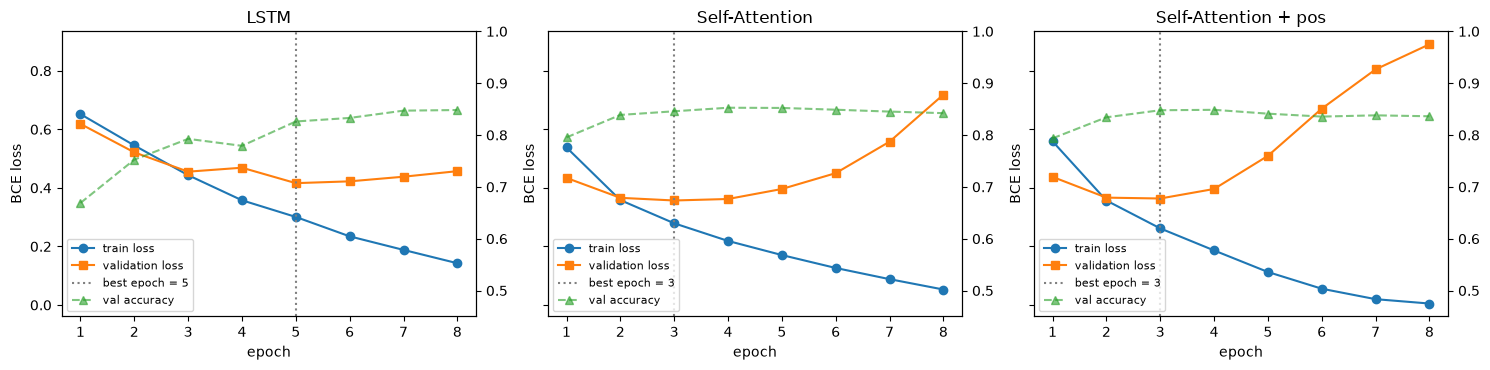

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (n, h) in zip(axes, histories.items()):
    ax.plot(h["epoch"], h["train_loss"], "o-", label="train loss")
    ax.plot(h["epoch"], h["val_loss"], "s-", label="validation loss")
    ax.axvline(infos[n]["best_epoch"], color="gray", ls=":", label=f"best epoch = {infos[n]['best_epoch']}")
    ax2 = ax.twinx()
    ax2.plot(h["epoch"], h["val_accuracy"], "^--", color="tab:green", alpha=0.6, label="val accuracy")
    ax2.set_ylim(0.45, 1.0)
    ax.set(title=n, xlabel="epoch", ylabel="BCE loss")
    l1, l2 = ax.get_legend_handles_labels(), ax2.get_legend_handles_labels()
    ax.legend(l1[0] + l2[0], l1[1] + l2[1], fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=120)
plt.show()

## 6. Experiment 3 - Attention visualization

Hai câu: "The cat that I adopted yesterday is sleeping." và "The book that I bought yesterday was expensive." Attention matrix A (T × T), hàng i = token i đang attend tới những token nào. So sánh bốn nguồn Q/K/V:

1. **Word2Vec, W = I**: Q = K = V = embedding Word2Vec, không có tham số học. Score chỉ là độ tương đồng giữa hai word vector.
2. **Word2Vec, W ngẫu nhiên**: cùng embedding, W_Q, W_K, W_V ngẫu nhiên N(0, 1/d). Dùng để thấy một heatmap "có pattern" không nhất thiết có ý nghĩa.
3. **Self-Attention (trained)**: lớp self-attention của classifier ở mục 5, train cho sentiment, không có vị trí.
4. **Self-Attention + pos (trained)**: như 3 nhưng có positional embedding.

tokens: ['the', 'cat', 'that', 'i', 'adopted', 'yesterday', 'is', 'sleeping'] | OOV trong vocabulary của model: []
tokens: ['the', 'book', 'that', 'i', 'bought', 'yesterday', 'was', 'expensive'] | OOV trong vocabulary của model: []


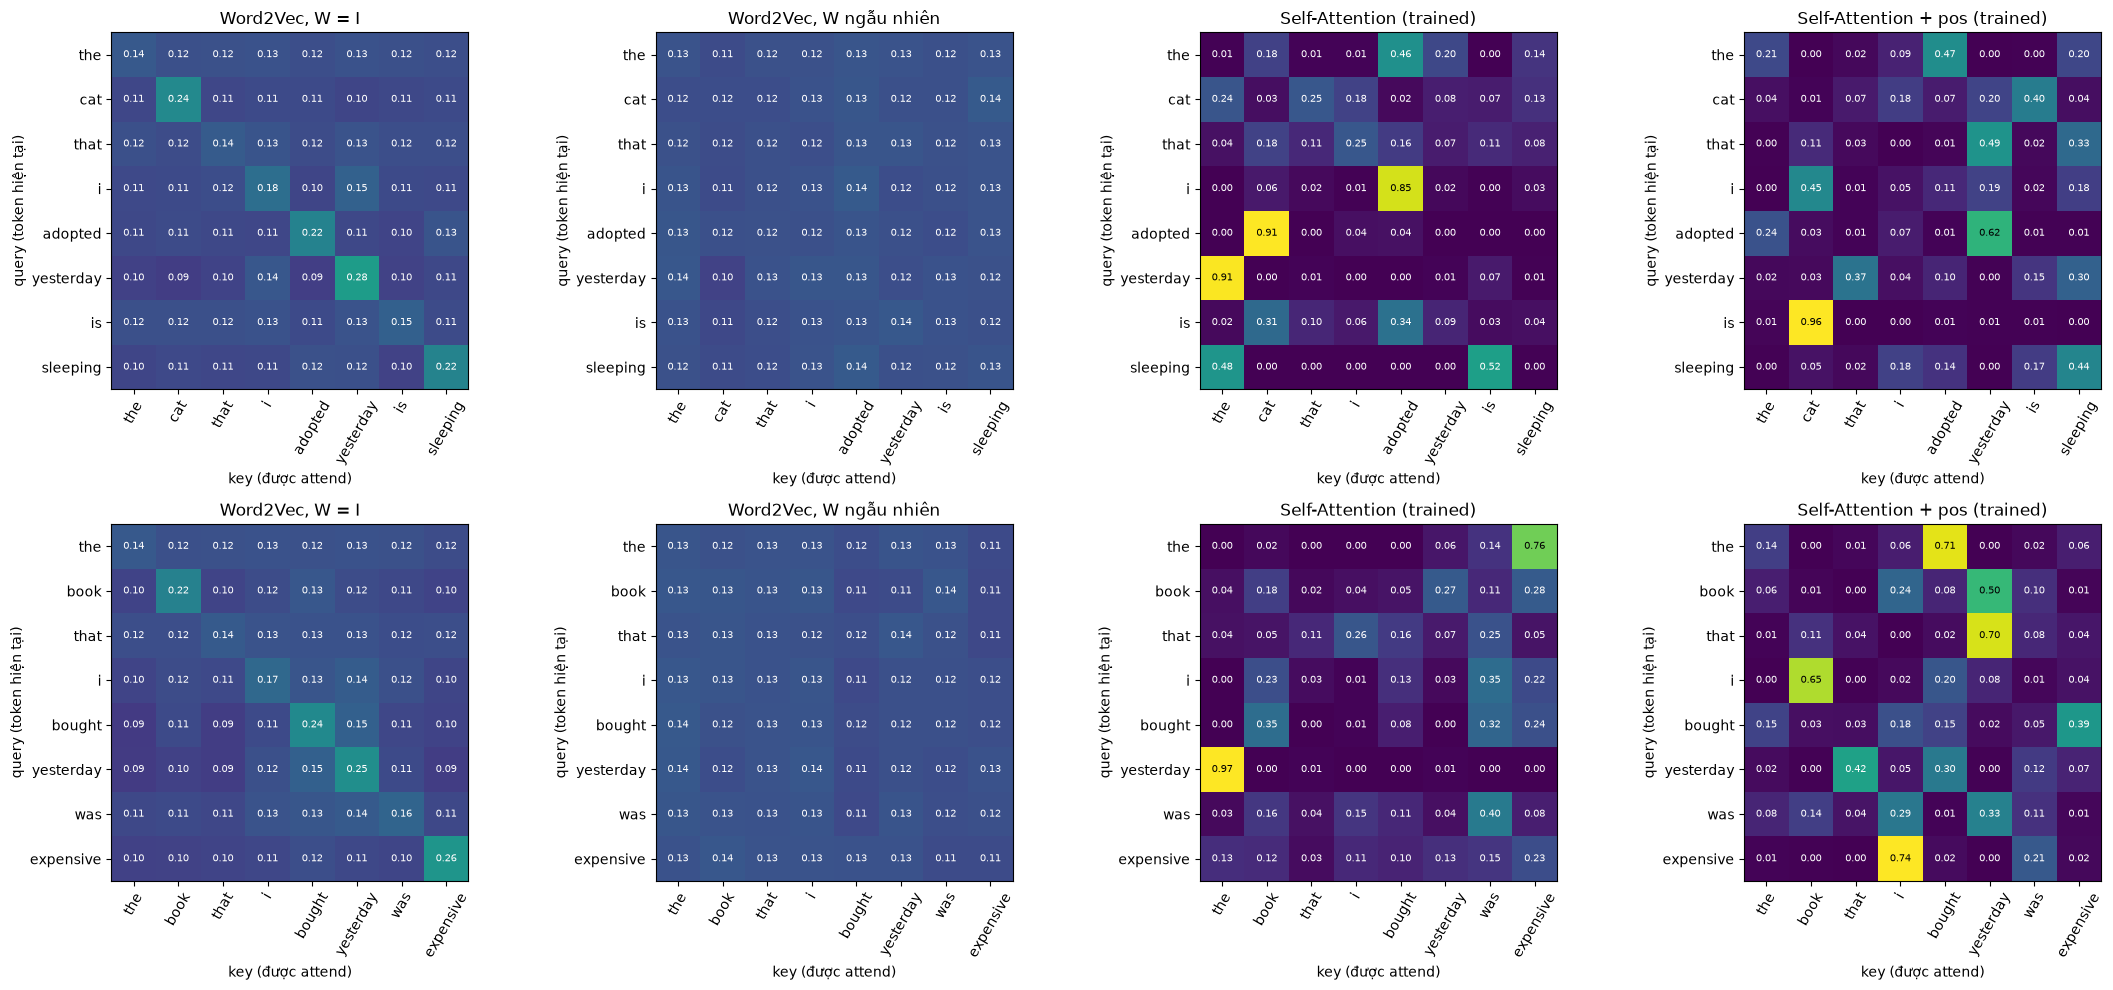

In [16]:
VIS_SENTS = ["The cat that I adopted yesterday is sleeping.", "The book that I bought yesterday was expensive."]
rng_w = np.random.default_rng(SEED)
W_rand = [rng_w.normal(scale=1 / np.sqrt(EMBED_DIM), size=(EMBED_DIM, HIDDEN)) for _ in range(3)]

@torch.no_grad()
def model_attention(model, tokens):
    ids, lens = to_tensors([encode(tokens)], max(len(tokens), 1))
    z, A, beta = model(ids, lens, return_attn=True)
    return A[0].numpy(), beta[0].numpy(), float(torch.sigmoid(z)[0])

def attention_sources(tokens):
    Xw = w2v_matrix(tokens)
    I = np.eye(EMBED_DIM)
    return {"Word2Vec, W = I": self_attention(Xw, I, I, I)["weights"],
            "Word2Vec, W ngẫu nhiên": self_attention(Xw, *W_rand)["weights"],
            "Self-Attention (trained)": model_attention(models["Self-Attention"], tokens)[0],
            "Self-Attention + pos (trained)": model_attention(models["Self-Attention + pos"], tokens)[0]}

vis = {s: (preprocess(s), attention_sources(preprocess(s))) for s in VIS_SENTS}
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for r, (s, (toks, srcs)) in enumerate(vis.items()):
    print("tokens:", toks, "| OOV trong vocabulary của model:", [t for t in toks if t not in stoi])
    for c, (src, A) in enumerate(srcs.items()):
        ax = axes[r, c]
        im = ax.imshow(A, cmap="viridis", vmin=0, vmax=max(0.5, A.max()))
        ax.set_xticks(range(len(toks)), toks, rotation=60)
        ax.set_yticks(range(len(toks)), toks)
        for i in range(len(toks)):
            for j in range(len(toks)):
                ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if A[i, j] < 0.6 * max(0.5, A.max()) else "black")
        ax.set(title=src, xlabel="key (được attend)", ylabel="query (token hiện tại)")
plt.tight_layout()
plt.savefig("attention_heatmap.png", dpi=110)
plt.show()

In [17]:
focus_rows = []
for s, (toks, srcs) in vis.items():
    for t in ["cat", "adopted", "sleeping", "book", "bought", "expensive"]:
        if t not in toks:
            continue
        i = toks.index(t)
        for src, A in srcs.items():
            top = np.argsort(-A[i])[:3]
            focus_rows.append({"token": t, "source": src, "self weight": A[i, i],
                               "top 3": ", ".join(f"{toks[j]} {A[i, j]:.2f}" for j in top)})
            for j, u in enumerate(toks):
                log("exp3_visualization", src, f"{t}->{u}", "-", "weight", A[i, j])
pd.DataFrame(focus_rows).set_index(["token", "source"])

self weight  \
token     source                                        
cat       Word2Vec, W = I                    0.236051   
          Word2Vec, W ngẫu nhiên             0.117966   
          Self-Attention (trained)           0.033214   
          Self-Attention + pos (trained)     0.009080   
adopted   Word2Vec, W = I                    0.221983   
          Word2Vec, W ngẫu nhiên             0.130025   
          Self-Attention (trained)           0.041780   
          Self-Attention + pos (trained)     0.009696   
sleeping  Word2Vec, W = I                    0.223122   
          Word2Vec, W ngẫu nhiên             0.129468   
          Self-Attention (trained)           0.003648   
          Self-Attention + pos (trained)     0.435142   
book      Word2Vec, W = I                    0.220644   
          Word2Vec, W ngẫu nhiên             0.133385   
          Self-Attention (trained)           0.181458   
          Self-Attention + pos (trained)     0.008915   
bought    Word2Vec, W = I                    0.237717   
          Word2Vec, W ngẫu nhiên             0.115320   
          Self-Attention (trained)           0.081945   
          Self-Attention + pos (trained)     0.146744   
expensive Word2Vec, W = I                    0.260025   
          Word2Vec, W ngẫu nhiên             0.113734   
          Self-Attention (trained)           0.228487   
          Self-Attention + pos (trained)     0.015908   

                                                                                top 3  
token     source                                                                       
cat       Word2Vec, W = I                       cat 0.24, sleeping 0.11, adopted 0.11  
          Word2Vec, W ngẫu nhiên                  sleeping 0.14, adopted 0.13, i 0.13  
          Self-Attention (trained)                        that 0.25, the 0.24, i 0.18  
          Self-Attention + pos (trained)              is 0.40, yesterday 0.20, i 0.18  
adopted   Word2Vec, W = I                       adopted 0.22, sleeping 0.13, cat 0.11  
          Word2Vec, W ngẫu nhiên                the 0.13, adopted 0.13, sleeping 0.13  
          Self-Attention (trained)                     cat 0.91, adopted 0.04, i 0.04  
          Self-Attention + pos (trained)             yesterday 0.62, the 0.24, i 0.07  
sleeping  Word2Vec, W = I                 sleeping 0.22, adopted 0.12, yesterday 0.12  
          Word2Vec, W ngẫu nhiên                  adopted 0.14, sleeping 0.13, i 0.13  
          Self-Attention (trained)                   is 0.52, the 0.48, sleeping 0.00  
          Self-Attention + pos (trained)               sleeping 0.44, i 0.18, is 0.17  
book      Word2Vec, W = I                              book 0.22, bought 0.13, i 0.12  
          Word2Vec, W ngẫu nhiên                           was 0.14, the 0.13, i 0.13  
          Self-Attention (trained)          expensive 0.28, yesterday 0.27, book 0.18  
          Self-Attention + pos (trained)             yesterday 0.50, i 0.24, was 0.10  
bought    Word2Vec, W = I                      bought 0.24, yesterday 0.15, book 0.11  
          Word2Vec, W ngẫu nhiên                          the 0.14, i 0.13, that 0.13  
          Self-Attention (trained)                book 0.35, was 0.32, expensive 0.24  
          Self-Attention + pos (trained)             expensive 0.39, i 0.18, the 0.15  
expensive Word2Vec, W = I                 expensive 0.26, bought 0.12, yesterday 0.11  
          Word2Vec, W ngẫu nhiên                         book 0.14, i 0.13, that 0.13  
          Self-Attention (trained)           expensive 0.23, was 0.15, yesterday 0.13  
          Self-Attention + pos (trained)                i 0.74, was 0.21, bought 0.02

**Attention pattern quan sát được (mô tả phân phối):**

- **Word2Vec, W = I:** mỗi token chú ý tới chính nó nhiều nhất (đường chéo 0.22 - 0.26), phần còn lại gần đều (0.10 - 0.13, mức đều là 0.125). Lý do: q_i · k_i = ‖x_i‖² thường lớn nhất. Ngoài đường chéo chỉ có độ tương đồng nhẹ về nghĩa: cat → sleeping 0.11, bought → yesterday 0.15.
- **W ngẫu nhiên:** gần như đều hoàn toàn (0.11 - 0.14). Không có pattern nào.
- **Self-Attention (trained, không vị trí):** rất sắc nét. adopted → cat 0.91, i → adopted 0.85, yesterday → the 0.91 (câu 1) và 0.97 (câu 2), sleeping → is 0.52 / the 0.48. Câu 2: bought → book 0.35, was 0.32, expensive 0.24; the → expensive 0.76.
- **Self-Attention + pos (trained):** pattern khác hẳn: is → cat 0.96, adopted → yesterday 0.62, cat → is 0.40, sleeping → sleeping 0.44; câu 2: bought → expensive 0.39, expensive → i 0.74, i → book 0.65.

**Cat, adopted, sleeping:** cat chú ý tới that/the/i (Self-Attention) hoặc is/yesterday (+ pos); adopted chú ý tới cat (0.91) hoặc yesterday (0.62); sleeping chú ý tới is/the hoặc chính nó.

**Pattern khác linguistic explanation.** Một vài ô trông giống quan hệ ngữ pháp: adopted → cat (động từ → tân ngữ trong "the cat that I adopted"), is → cat (động từ → chủ ngữ), bought → book. Nhưng không thể kết luận model "hiểu ngữ pháp":

1. Hai model trained cho hai heatmap rất khác nhau trên cùng câu, dù accuracy gần bằng nhau (0.837 và 0.833). Nếu pattern là cú pháp thì phải ổn định hơn.
2. Nhiều ô nổi bật không có diễn giải ngôn ngữ nào: yesterday → the 0.91 / 0.97, the → expensive 0.76, expensive → i 0.74.
3. Self-Attention không có thông tin vị trí: hàng của "adopted" chỉ phụ thuộc vào tập từ trong câu, không phụ thuộc thứ tự. Đảo thành "the adopted that I cat ..." vẫn cho adopted → cat 0.91. Model không thể biết "cat" là tân ngữ của "adopted" dựa trên cấu trúc câu.
4. Model chỉ được train cho sentiment trên IMDb, không có tín hiệu nào về cú pháp.

Heatmap là bằng chứng về **cách trọng số được phân phối**, không phải bằng chứng về reasoning hay linguistic understanding. Muốn kiểm tra một giả thuyết cú pháp phải có thí nghiệm can thiệp (đổi chủ ngữ, đổi thứ tự) và đo trên nhiều câu.

## 7. Experiment 4 - RNN context vs attention context

### 7.1 Thứ tự từ

Các cặp câu có cùng bag-of-words. Self-attention không có vị trí là permutation-equivariant (hoán vị input thì H hoán vị theo), pooling Σ β_t h_t không phụ thuộc thứ tự, nên output phải **giống hệt nhau**.

In [18]:
def proba_texts(model, texts):
    ids, lens = to_tensors([encode(preprocess(t)) for t in texts])
    return predict_proba(model, ids, lens)

@torch.no_grad()
def predict_logit(model, ids, lens, batch=512):
    model.eval()
    return torch.cat([model(ids[i:i + batch], lens[i:i + batch]) for i in range(0, len(ids), batch)]).numpy()

def logit_texts(model, texts):
    ids, lens = to_tensors([encode(preprocess(t)) for t in texts])
    return predict_logit(model, ids, lens)

order_pairs = [
    ("this movie is good", "this movie is not good"),
    ("the movie was not bad , it was good", "the movie was not good , it was bad"),
    ("i expected it to be bad but it was great", "i expected it to be great but it was bad"),
    ("great actors , boring story", "boring actors , great story"),
    ("i loved it at first but now i hate it", "i hated it at first but now i love it"),
    ("good is movie this", "this movie is good"),
]
rows = []
for s1, s2 in order_pairs:
    same_bag = sorted(preprocess(s1)) == sorted(preprocess(s2))
    r = {"S1": s1, "S2": s2, "cùng bag-of-words": same_bag,
         "TF-IDF+LR": tuple(baseline.predict_proba([s1, s2])[:, 1].round(3))}
    for n, m in models.items():
        r[n] = tuple(proba_texts(m, [s1, s2]).round(3))
    rows.append(r)
    for n in ["TF-IDF+LR"] + list(models):
        log("exp4_order", n, f"{s1} | {s2}", "-", "p_pos_S1", r[n][0])
        log("exp4_order", n, f"{s1} | {s2}", "-", "p_pos_S2", r[n][1])
pd.DataFrame(rows)

,S1,S2,cùng bag-of-words,TF-IDF+LR,LSTM,Self-Attention,Self-Attention + pos
0,this movie is good,this movie is not good,False,"(0.825, 0.37)","(0.679, 0.462)","(1.0, 0.813)","(1.0, 1.0)"
1,"the movie was not bad , it was good","the movie was not good , it was bad",True,"(0.002, 0.002)","(0.258, 0.134)","(0.035, 0.035)","(0.0, 0.007)"
2,i expected it to be bad but it was great,i expected it to be great but it was bad,True,"(0.37, 0.37)","(0.694, 0.328)","(0.106, 0.106)","(0.896, 0.026)"
3,"great actors , boring story","boring actors , great story",True,"(0.139, 0.139)","(0.21, 0.405)","(0.0, 0.0)","(0.937, 0.03)"
4,i loved it at first but now i hate it,i hated it at first but now i love it,False,"(0.993, 0.934)","(0.923, 0.873)","(1.0, 1.0)","(1.0, 1.0)"
5,good is movie this,this movie is good,True,"(0.825, 0.825)","(0.453, 0.679)","(1.0, 1.0)","(1.0, 1.0)"


### 7.2 Long-range dependency

Lặp lại Experiment 6 của LAB 05: câu quyết định sentiment đặt ở đầu / giữa / cuối một đoạn filler trung tính. Separation = P(pos | bản positive) − P(pos | bản negative), trung bình trên 5 cặp câu × 4 cách chọn filler.

In [19]:
FILLER = [
    "the film was shot in a small town in the north of the country during the winter of that year .",
    "it runs for about two hours and was released in theaters in the spring .",
    "the story follows a man who moves back to his home town after many years away .",
    "he takes a job at the local school and meets some of the people he grew up with .",
    "his sister works at the hospital and his father still runs the family store on the main street .",
    "most of the scenes take place in the house , the school and the store .",
    "the cast includes several actors who also appeared in the director 's previous film .",
    "the music was written by a composer who has worked on many television series .",
    "there is also a second story about a young woman who is looking for her brother .",
    "the two stories meet in the last part of the film when the town holds its annual festival .",
    "the dvd includes a commentary track and a short documentary about the production .",
    "i watched it on a sunday afternoon with two friends .",
]
KEY_PAIRS = [
    ("the movie was ultimately excellent .", "the movie was ultimately terrible ."),
    ("overall it is a great film .", "overall it is an awful film ."),
    ("i loved every minute of it .", "i hated every minute of it ."),
    ("the acting was wonderful .", "the acting was horrible ."),
    ("highly recommended .", "a complete waste of time ."),
]

def build(key, n_filler, position, seed):
    r = np.random.default_rng(seed)
    filler = list(r.choice(FILLER, size=n_filler, replace=n_filler > len(FILLER)))
    pos = {"beginning": 0, "middle": n_filler // 2, "end": n_filler}[position]
    return " ".join(filler[:pos] + [key] + filler[pos:])

long_rows = []
scorers = {n: (lambda x, m=m: logit_texts(m, x)) for n, m in models.items()}
scorers["TF-IDF+LR"] = lambda x: baseline.decision_function(x)
sigmoid = lambda z: 1 / (1 + np.exp(-z))
for n_filler in [2, 6, 10]:
    for position in ["beginning", "middle", "end"]:
        tp, tn = [], []
        for k, (kp, kn) in enumerate(KEY_PAIRS):
            for s in range(4):
                tp.append(build(kp, n_filler, position, 100 * k + s))
                tn.append(build(kn, n_filler, position, 100 * k + s))
        assert max(len(preprocess(x)) for x in tp + tn) <= MAX_LEN
        for n, f in scorers.items():
            zp, zn = f(tp), f(tn)
            pp, pn = sigmoid(zp), sigmoid(zn)
            long_rows.append({"filler": n_filler, "avg_tokens": np.mean([len(preprocess(x)) for x in tp]),
                              "position": position, "model": n, "separation": (pp - pn).mean(),
                              "logit separation": (zp - zn).mean(), "P(pos|pos)": pp.mean(), "P(pos|neg)": pn.mean(),
                              "accuracy": ((pp >= 0.5).sum() + (pn < 0.5).sum()) / (2 * len(pp))})
long_df = pd.DataFrame(long_rows)
for _, r in long_df.iterrows():
    log("exp4_long_range", r["model"], f"filler={r['filler']} {r['position']}", "-", "separation", r["separation"])
    log("exp4_long_range", r["model"], f"filler={r['filler']} {r['position']}", "-", "accuracy", r["accuracy"])
    log("exp4_long_range", r["model"], f"filler={r['filler']} {r['position']}", "-", "logit_separation", r["logit separation"])
display(long_df.pivot_table(index=["filler", "avg_tokens"], columns=["model", "position"], values="separation").round(3))
display(long_df.pivot_table(index="filler", columns=["model", "position"], values="logit separation").round(2))
long_df.pivot_table(index="filler", columns=["model", "position"], values="accuracy").round(3)

model                  LSTM               Self-Attention                \
position          beginning    end middle      beginning    end middle   
filler avg_tokens                                                        
2      36.85          0.297  0.510  0.269          0.345  0.345  0.345   
6      98.95          0.003  0.413  0.004          0.027  0.027  0.027   
10     159.15         0.000  0.396  0.000          0.013  0.013  0.013   

model             Self-Attention + pos               TF-IDF+LR                
position                     beginning    end middle beginning    end middle  
filler avg_tokens                                                             
2      36.85                     0.379  0.446  0.456     0.379  0.379  0.379  
6      98.95                     0.040  0.043  0.064     0.085  0.085  0.085  
10     159.15                    0.008  0.011  0.015     0.038  0.038  0.038

model         LSTM              Self-Attention               \
position beginning   end middle      beginning   end middle   
filler                                                        
2             1.74  3.63   1.62           5.69  5.69   5.69   
6             0.04  3.47   0.05           2.89  2.89   2.89   
10            0.00  3.45   0.00           2.12  2.12   2.12   

model    Self-Attention + pos              TF-IDF+LR               
position            beginning   end middle beginning   end middle  
filler                                                             
2                        6.54  6.64   6.83      2.90  2.90   2.90  
6                        2.69  2.51   2.88      1.69  1.69   1.69  
10                       1.92  1.81   1.74      1.32  1.32   1.32

model         LSTM               Self-Attention                \
position beginning    end middle      beginning    end middle   
filler                                                          
2              0.7  0.800  0.675          0.675  0.675  0.675   
6              0.5  0.750  0.500          0.500  0.500  0.500   
10             0.5  0.675  0.500          0.500  0.500  0.500   

model    Self-Attention + pos               TF-IDF+LR                
position            beginning    end middle beginning    end middle  
filler                                                               
2                         0.7  0.725  0.725     0.725  0.725  0.725  
6                         0.5  0.500  0.500     0.500  0.500  0.500  
10                        0.5  0.500  0.500     0.500  0.500  0.500

### 7.3 Representation tập trung vào vị trí nào?

Với 300 review test dài ≥ 200 token (bị cắt còn 200): (a) ‖∂z/∂e_t‖, độ nhạy của logit theo embedding ở vị trí t, cho cả ba model (giống LAB 05); (b) pooling weight β_t trung bình theo vị trí cho hai model attention. Mỗi đường được chuẩn hoá để tổng = 1, rồi tính phần khối lượng rơi vào 20 vị trí cuối (181 - 200). Nếu chia đều thì 20 vị trí cuối chiếm 10%.

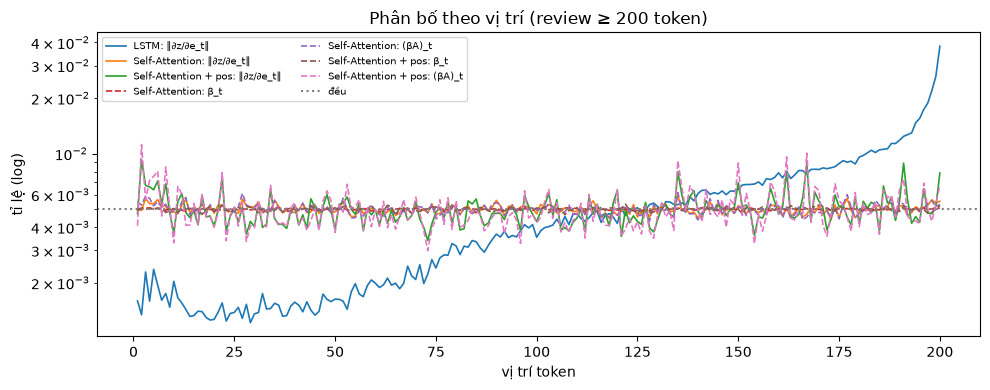

,% ở 20 vị trí đầu,% khối lượng ở 20 vị trí cuối
LSTM: ‖∂z/∂e_t‖,3.19,29.73
Self-Attention: ‖∂z/∂e_t‖,10.26,10.27
Self-Attention + pos: ‖∂z/∂e_t‖,11.05,10.90
Self-Attention: β_t,10.00,10.02
Self-Attention: (βA)_t,10.42,10.30
Self-Attention + pos: β_t,9.94,9.99
Self-Attention + pos: (βA)_t,11.45,10.59


In [20]:
long_idx = np.where(len_test >= MAX_LEN)[0][:300]
ids_long, lens_long = to_tensors([ids_test[i] for i in long_idx])
profiles = {}
for n, m in models.items():
    m.eval()
    e = m.embed(ids_long).detach().requires_grad_(True)
    m.forward_embedded(e, lens_long).sum().backward()
    g = e.grad.norm(dim=2).mean(0).numpy()
    profiles[f"{n}: ‖∂z/∂e_t‖"] = g / g.sum()
for n in ["Self-Attention", "Self-Attention + pos"]:
    with torch.no_grad():
        _, A_l, beta_l = models[n](ids_long, lens_long, return_attn=True)
    profiles[f"{n}: β_t"] = beta_l.mean(0).numpy()
    profiles[f"{n}: (βA)_t"] = (beta_l[:, None, :] @ A_l)[:, 0, :].mean(0).numpy()   # attention rollout về token input
prof = pd.DataFrame(profiles, index=np.arange(1, MAX_LEN + 1))
share = (prof.loc[181:200].sum() * 100).rename("% khối lượng ở 20 vị trí cuối")
first = (prof.loc[1:20].sum() * 100).rename("% ở 20 vị trí đầu")
for k, v in share.items():
    log("exp4_position_profile", k, "last20", "test", "share_pct", v)
for k, v in first.items():
    log("exp4_position_profile", k, "first20", "test", "share_pct", v)
fig, ax = plt.subplots(figsize=(10, 4))
for c in prof.columns:
    ax.semilogy(prof.index, prof[c], label=c, lw=1.2, ls="-" if "∂z" in c else "--")
ax.axhline(1 / MAX_LEN, color="gray", ls=":", label="đều")
ax.set(title="Phân bố theo vị trí (review ≥ 200 token)", xlabel="vị trí token", ylabel="tỉ lệ (log)")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("position_profile.png", dpi=120)
plt.show()
pd.concat([first, share], axis=1).round(2)

In [21]:
bins = [0, 50, 100, 200, 400, 10**5]
labels = ["≤50", "51-100", "101-200", "201-400", ">400"]
bucket = pd.cut(len_test, bins=bins, labels=labels)
acc_len = pd.DataFrame({n: pd.Series((test_proba[n] >= 0.5) == y_test).groupby(bucket, observed=True).mean()
                        for n in models} | {"TF-IDF + LR": pd.Series((p_base >= 0.5) == y_test).groupby(bucket, observed=True).mean()})
acc_len.insert(0, "n_reviews", pd.Series(bucket).value_counts().reindex(labels).values)
for b, r in acc_len.iterrows():
    for k, v in r.items():
        log("exp4_acc_by_length", k, b, "test", "accuracy" if k != "n_reviews" else "n_reviews", v)
acc_len.round(4)

,n_reviews,LSTM,Self-Attention,Self-Attention + pos,TF-IDF + LR
≤50,635,0.8772,0.8772,0.8598,0.8913
51-100,2485,0.8652,0.8640,0.8551,0.8942
101-200,11603,0.8606,0.8591,0.8584,0.8900
201-400,6887,0.7854,0.8157,0.8092,0.8883
>400,3068,0.7324,0.7676,0.7643,0.8892


**Kết quả (test, max_length 200):**

| Model | Context representation | F1 | Train time | Params (phần recurrent / attention) |
|---|---|---|---|---|
| LSTM | h_T | 0.827 | 389 s (46.7 s/epoch) | 2,118,089 (117,760) |
| Self-Attention | Σ β_t h_t | **0.842** | 270 s (31.7 s/epoch) | 2,038,857 (38,528) |
| Self-Attention + pos | Σ β_t h_t | 0.834 | 300 s (35.3 s/epoch) | 2,058,857 (58,528) |

Attention tốt hơn LSTM khoảng 1 - 1.5 điểm F1 và train nhanh hơn khoảng 1.4 lần, nhưng vẫn kém TF-IDF + LR (0.890). Attention học nhanh hơn (best epoch 3 so với 5) và overfit mạnh hơn: validation loss của Self-Attention từ 0.357 (epoch 3) lên 0.719 (epoch 8); Self-Attention + pos có train loss 0.005 ở epoch 8.

**Representation của hai model khác nhau ở đâu:**

1. **Thứ tự.** Self-Attention không có vị trí cho P(pos) **giống hệt nhau** với mọi cặp cùng bag-of-words (0.035/0.035, 0.106/0.106, 0.000/0.000, 1.000/1.000), đúng như TF-IDF. Về mặt thứ tự, nó là một bag-of-words phi tuyến. LSTM phân biệt được thứ tự. Self-Attention + pos phân biệt mạnh hơn cả LSTM: "expected bad but it was great" 0.896 so với "expected great but it was bad" 0.026 (LSTM 0.694 so với 0.328). Tuy vậy "this movie is not good" vẫn là 1.000 với model + pos.
2. **Vị trí được dùng.** Với review ≥ 200 token, 29.7% độ nhạy ‖∂z/∂e_t‖ của LSTM nằm ở 20 vị trí cuối và chỉ 3.2% ở 20 vị trí đầu (đều là 10%). Hai model attention phẳng: khoảng 10% ở cả đầu và cuối (`position_profile.png`). LSTM có recency bias, attention thì không.
3. **Long-range (từ khoá ở đầu / giữa / cuối):** LSTM chỉ nhận ra khi câu quyết định ở cuối (logit separation 3.45 - 3.63), còn ở đầu và giữa thì về 0 khi filler ≥ 6 câu. Self-Attention cho **cùng kết quả ở mọi vị trí** (logit separation 5.69 / 2.89 / 2.12 với 37 / 99 / 159 token), Self-Attention + pos gần như vậy. Đổi lại, separation giảm theo độ dài vì β gần đều (xem mục 11): context là một kiểu trung bình, nên một câu quyết định giữa 150 token trung tính bị pha loãng. Với filler ≥ 6 câu, accuracy của các model attention về 0.5: cả bản positive lẫn negative bị đẩy về cùng một phía, dù logit vẫn xếp đúng thứ tự.
4. **Theo độ dài review:** với review ≤ 200 token, LSTM và Self-Attention bằng nhau (0.86 - 0.88). Với review dài hơn, attention tốt hơn: 0.816 so với 0.785 (201 - 400 token) và 0.768 so với 0.732 (> 400 token).

Tóm lại: LSTM nén cả sequence vào một trạng thái cuối, nên nhạy với thứ tự nhưng thiên về phần cuối. Attention nối trực tiếp mọi vị trí tới context (đường đi dài 1 - 2 bước), không có recency bias, nhưng không có vị trí thì không biết thứ tự, và tổng có trọng số dễ bị pha loãng.

## 8. Experiment 5 - Sequence length và computational cost

Số phần tử của attention matrix là T². Đo thực tế với một câu (batch 1), không tính gradient:

- NumPy `scaled_dot_product_attention` với Q, K, V ∈ ℝ^(T × 64);
- lớp `SelfAttention` (100 → 128) của PyTorch, và `nn.LSTM` (100 → 128) để so sánh.

Bộ nhớ của A tính cho batch 64, float32: 64 · T² · 4 byte.

In [22]:
def timeit(f, min_time=0.3):
    f()                                         # warm-up
    n, t0 = 0, time.perf_counter()
    while time.perf_counter() - t0 < min_time:
        f(); n += 1
    return (time.perf_counter() - t0) / n

cost_rows = []
torch.manual_seed(SEED)
sa_layer, lstm_layer = SelfAttention(EMBED_DIM, HIDDEN).eval(), nn.LSTM(EMBED_DIM, HIDDEN, batch_first=True).eval()
for T in [10, 100, 500, 1000, 2000, 4000]:
    Qn, Kn, Vn = (np.random.default_rng(T).normal(size=(T, 64)) for _ in range(3))
    xt = torch.randn(1, T, EMBED_DIM)
    mt = torch.ones(1, T, dtype=torch.bool)
    with torch.no_grad():
        t_np = timeit(lambda: scaled_dot_product_attention(Qn, Kn, Vn))
        t_sa = timeit(lambda: sa_layer(xt, mt))
        t_lstm = timeit(lambda: lstm_layer(xt))
    cost_rows.append({"T": T, "attention matrix": f"{T}×{T}", "phần tử T²": T * T,
                      "A float32, 1 câu (MB)": T * T * 4 / 2**20, "A float32, batch 64 (MB)": 64 * T * T * 4 / 2**20,
                      "NumPy attention (ms)": 1000 * t_np, "PyTorch self-attention (ms)": 1000 * t_sa,
                      "PyTorch LSTM (ms)": 1000 * t_lstm})
cost_df = pd.DataFrame(cost_rows).set_index("T")
for T, r in cost_df.iterrows():
    for k, v in r.items():
        if k != "attention matrix":
            log("exp5_cost", "-", f"T={T}", "-", k, v)
cost_df.round(3)

,attention matrix,phần tử T²,"A float32, 1 câu (MB)","A float32, batch 64 (MB)",NumPy attention (ms),PyTorch self-attention (ms),PyTorch LSTM (ms)
T,,,,,,,
10,10×10,100,0.000,0.024,0.041,0.241,0.376
100,100×100,10000,0.038,2.441,0.311,0.376,0.858
500,500×500,250000,0.954,61.035,7.962,1.292,3.102
1000,1000×1000,1000000,3.815,244.141,30.548,4.113,7.804
2000,2000×2000,4000000,15.259,976.562,115.032,14.240,15.108
4000,4000×4000,16000000,61.035,3906.250,394.329,52.030,30.445


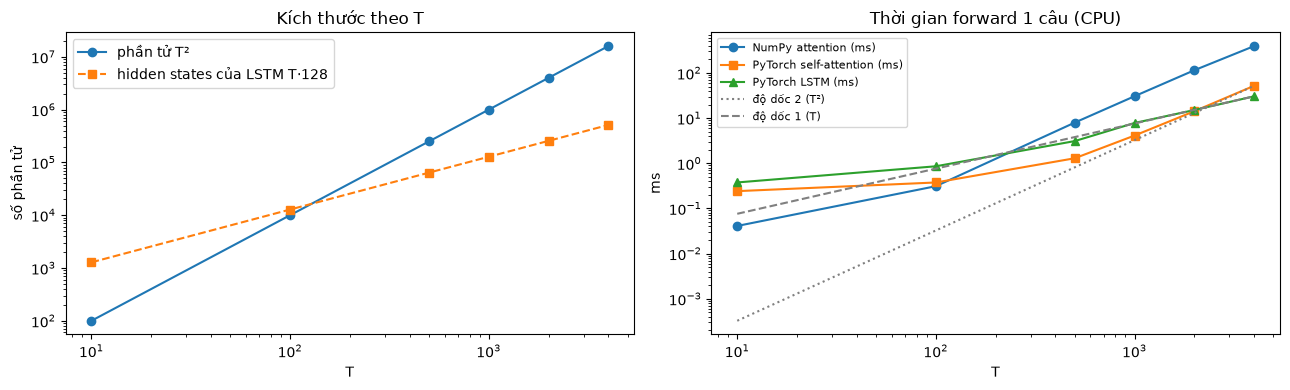

Độ dốc log-log trong khoảng T = 500 - 4000: {'NumPy attention (ms)': np.float64(1.88), 'PyTorch self-attention (ms)': np.float64(1.78), 'PyTorch LSTM (ms)': np.float64(1.08)}


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
Tv = cost_df.index.values
axes[0].loglog(Tv, Tv ** 2, "o-", label="phần tử T²")
axes[0].loglog(Tv, Tv * HIDDEN, "s--", label="hidden states của LSTM T·128")
axes[0].set(title="Kích thước theo T", xlabel="T", ylabel="số phần tử")
axes[0].legend()
for c, mk in [("NumPy attention (ms)", "o-"), ("PyTorch self-attention (ms)", "s-"), ("PyTorch LSTM (ms)", "^-")]:
    axes[1].loglog(Tv, cost_df[c], mk, label=c)
ref = cost_df["PyTorch self-attention (ms)"].iloc[-1]
axes[1].loglog(Tv, ref * (Tv / Tv[-1]) ** 2, ":", color="gray", label="độ dốc 2 (T²)")
axes[1].loglog(Tv, cost_df["PyTorch LSTM (ms)"].iloc[-1] * (Tv / Tv[-1]), "--", color="gray", label="độ dốc 1 (T)")
axes[1].set(title="Thời gian forward 1 câu (CPU)", xlabel="T", ylabel="ms")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("sequence_cost.png", dpi=120)
plt.show()
slopes = {c: np.polyfit(np.log(Tv[2:]), np.log(cost_df[c].values[2:]), 1)[0]
          for c in ["NumPy attention (ms)", "PyTorch self-attention (ms)", "PyTorch LSTM (ms)"]}
for k, v in slopes.items():
    log("exp5_cost", k, "T=500..4000", "-", "loglog_slope", v)
print("Độ dốc log-log trong khoảng T = 500 - 4000:", {k: round(v, 2) for k, v in slopes.items()})

**Kích thước:** T² tăng từ 100 (T = 10) lên 16 triệu (T = 4000). Với batch 64, float32, một head, riêng ma trận A đã cần 244 MB ở T = 1000 và 3.9 GB ở T = 4000. Ở T = 10,000 là 24 GB cho một layer, một head.

**Thời gian đo được (1 câu, CPU):**

- NumPy attention: 0.041 ms (T = 10) → 30.5 ms (T = 1000) → 394 ms (T = 4000). Độ dốc log-log 1.88, gần 2.
- PyTorch self-attention: độ dốc 1.78. LSTM: độ dốc 1.08, gần tuyến tính.
- Từ 10 lên 1000 token, NumPy attention chậm hơn khoảng 745 lần chứ không phải 10,000 lần như lý thuyết, vì với T nhỏ chi phí cố định (gọi hàm, cấp phát) chiếm phần lớn. Từ 1000 lên 4000 (lý thuyết ×16) đo được ×12.9.
- Với T ≤ 1000, self-attention **nhanh hơn** LSTM (T = 1000: 4.1 ms so với 7.8 ms) vì phép nhân ma trận chạy song song, còn LSTM phải tính tuần tự từng bước. Hai đường cắt nhau ở khoảng T = 2000 (14.2 so với 15.1 ms). Ở T = 4000, attention đã chậm hơn (52 ms so với 30 ms).

**Vì sao self-attention có vấn đề khi sequence rất dài:** mỗi token tính score với mọi token khác, nên cả thời gian O(T² d) lẫn bộ nhớ O(T²) đều tăng theo bình phương. Gấp đôi T thì A lớn gấp 4. LSTM chỉ cần O(T) nhưng không song song được. Attention giải quyết vấn đề đường đi dài của RNN, nhưng đổi lại phải trả chi phí bình phương.

## 9. Evaluation

In [24]:
final = pd.DataFrame([{"model": "TF-IDF + LR", "representation": "TF-IDF (sparse, toàn bộ review)", **m_base,
                       "train_time_s": base_time, "params": base_params}] +
                     [{"model": n, "representation": {"LSTM": "h_T (recurrent state)"}.get(n, "Σ β_t h_t (weighted combination)"),
                       **test_metrics[n], "train_time_s": infos[n]["train_time_s"], "params": infos[n]["params"]}
                      for n in models]).set_index("model")
for n, r in final.iterrows():
    for k in ["accuracy", "precision", "recall", "f1"]:
        log("evaluation", n, "final", "test", k, r[k])
final.round(4)

,representation,accuracy,precision,recall,f1,train_time_s,params
model,,,,,,,
TF-IDF + LR,"TF-IDF (sparse, toàn bộ review)",0.8899,0.8915,0.8894,0.8904,5.2208,43173
LSTM,h_T (recurrent state),0.8246,0.8194,0.8354,0.8273,389.4278,2118089
Self-Attention,Σ β_t h_t (weighted combination),0.8366,0.8186,0.8673,0.8422,270.0838,2038857
Self-Attention + pos,Σ β_t h_t (weighted combination),0.8327,0.8324,0.8356,0.8340,300.1236,2058857


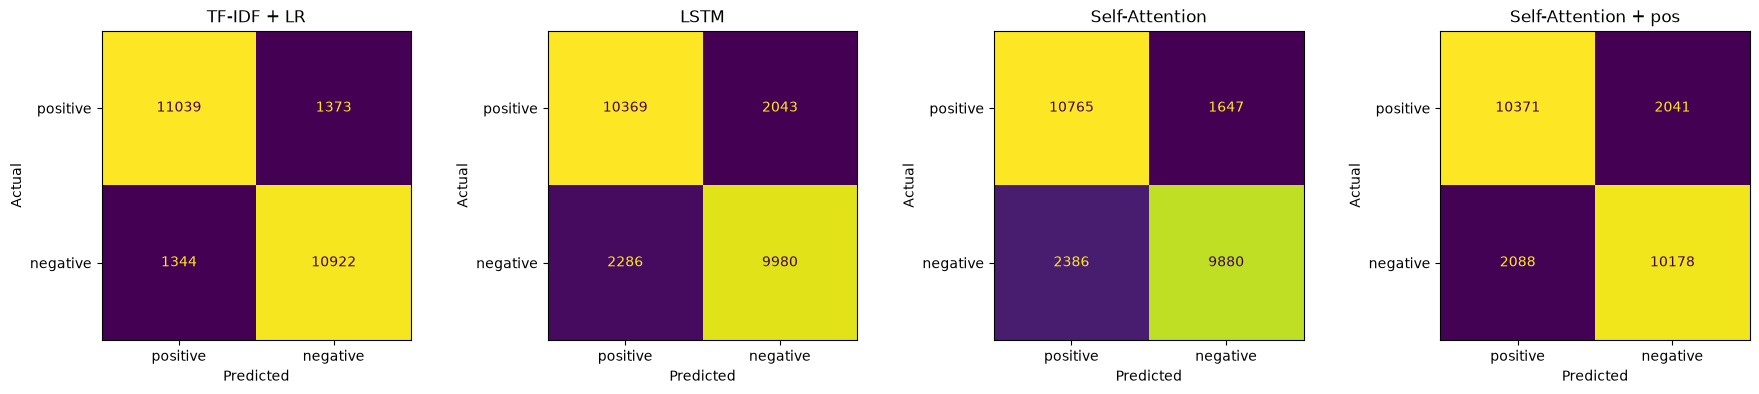

,TP,FN,FP,TN
model,,,,
TF-IDF + LR,11039,1373,1344,10922
LSTM,10369,2043,2286,9980
Self-Attention,10765,1647,2386,9880
Self-Attention + pos,10371,2041,2088,10178


In [25]:
preds = {"TF-IDF + LR": (p_base >= 0.5).astype(int)} | {n: (test_proba[n] >= 0.5).astype(int) for n in models}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
cm_rows = []
for ax, (n, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["positive", "negative"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set(title=n, xlabel="Predicted", ylabel="Actual")
    tp, fn, fp, tn = cm.ravel()
    cm_rows.append({"model": n, "TP": tp, "FN": fn, "FP": fp, "TN": tn})
    for k, v in cm_rows[-1].items():
        if k != "model":
            log("evaluation", n, "confusion_matrix", "test", k, v)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()
pd.DataFrame(cm_rows).set_index("model")

- TF-IDF + LR vẫn tốt nhất (F1 0.890). Trong các model neural, Self-Attention cao nhất (0.842) > Self-Attention + pos (0.834) > LSTM (0.827).
- Self-Attention lệch về positive: FP 2,386 > FN 1,647, nên recall 0.867 > precision 0.819. Self-Attention + pos cân bằng hơn (FN 2,041, FP 2,088). LSTM có FN 2,043, FP 2,286.
- Self-Attention và LSTM sai ở những chỗ khá khác nhau: 2,468 review cả hai cùng sai, 1,565 review chỉ Self-Attention sai, 1,861 review chỉ LSTM sai.
- Chi phí: model attention có ít tham số hơn LSTM một chút (2.04 triệu so với 2.12 triệu, phần lớn là embedding) và train nhanh hơn, nhưng vẫn chậm hơn TF-IDF khoảng 50 lần.

## 10. Application - Context-aware sentiment

raw text → tokenizer → embedding → self-attention → context vector → classifier → sentiment. Model dùng: model attention có validation F1 cao hơn. Với mỗi câu: prediction, P(pos), logit z, và ba cách nhìn "token nào quan trọng":

- β_t: pooling weight trên hàng t của H (H đã trộn thông tin của nhiều token);
- (βA)_t = Σ_i β_i A_it: attention rollout, phần của context vector đến từ value của token input t;
- occlusion Δz_t = z(câu) − z(câu bỏ token t): thay đổi thật của logit khi bỏ token, dùng để đối chiếu.

Bên phải là attention matrix A.

Model attention dùng cho application / error analysis: Self-Attention
Self-Attention: max |P padded - P không pad| = 0.00e+00
Self-Attention + pos: max |P padded - P không pad| = 1.75e-10


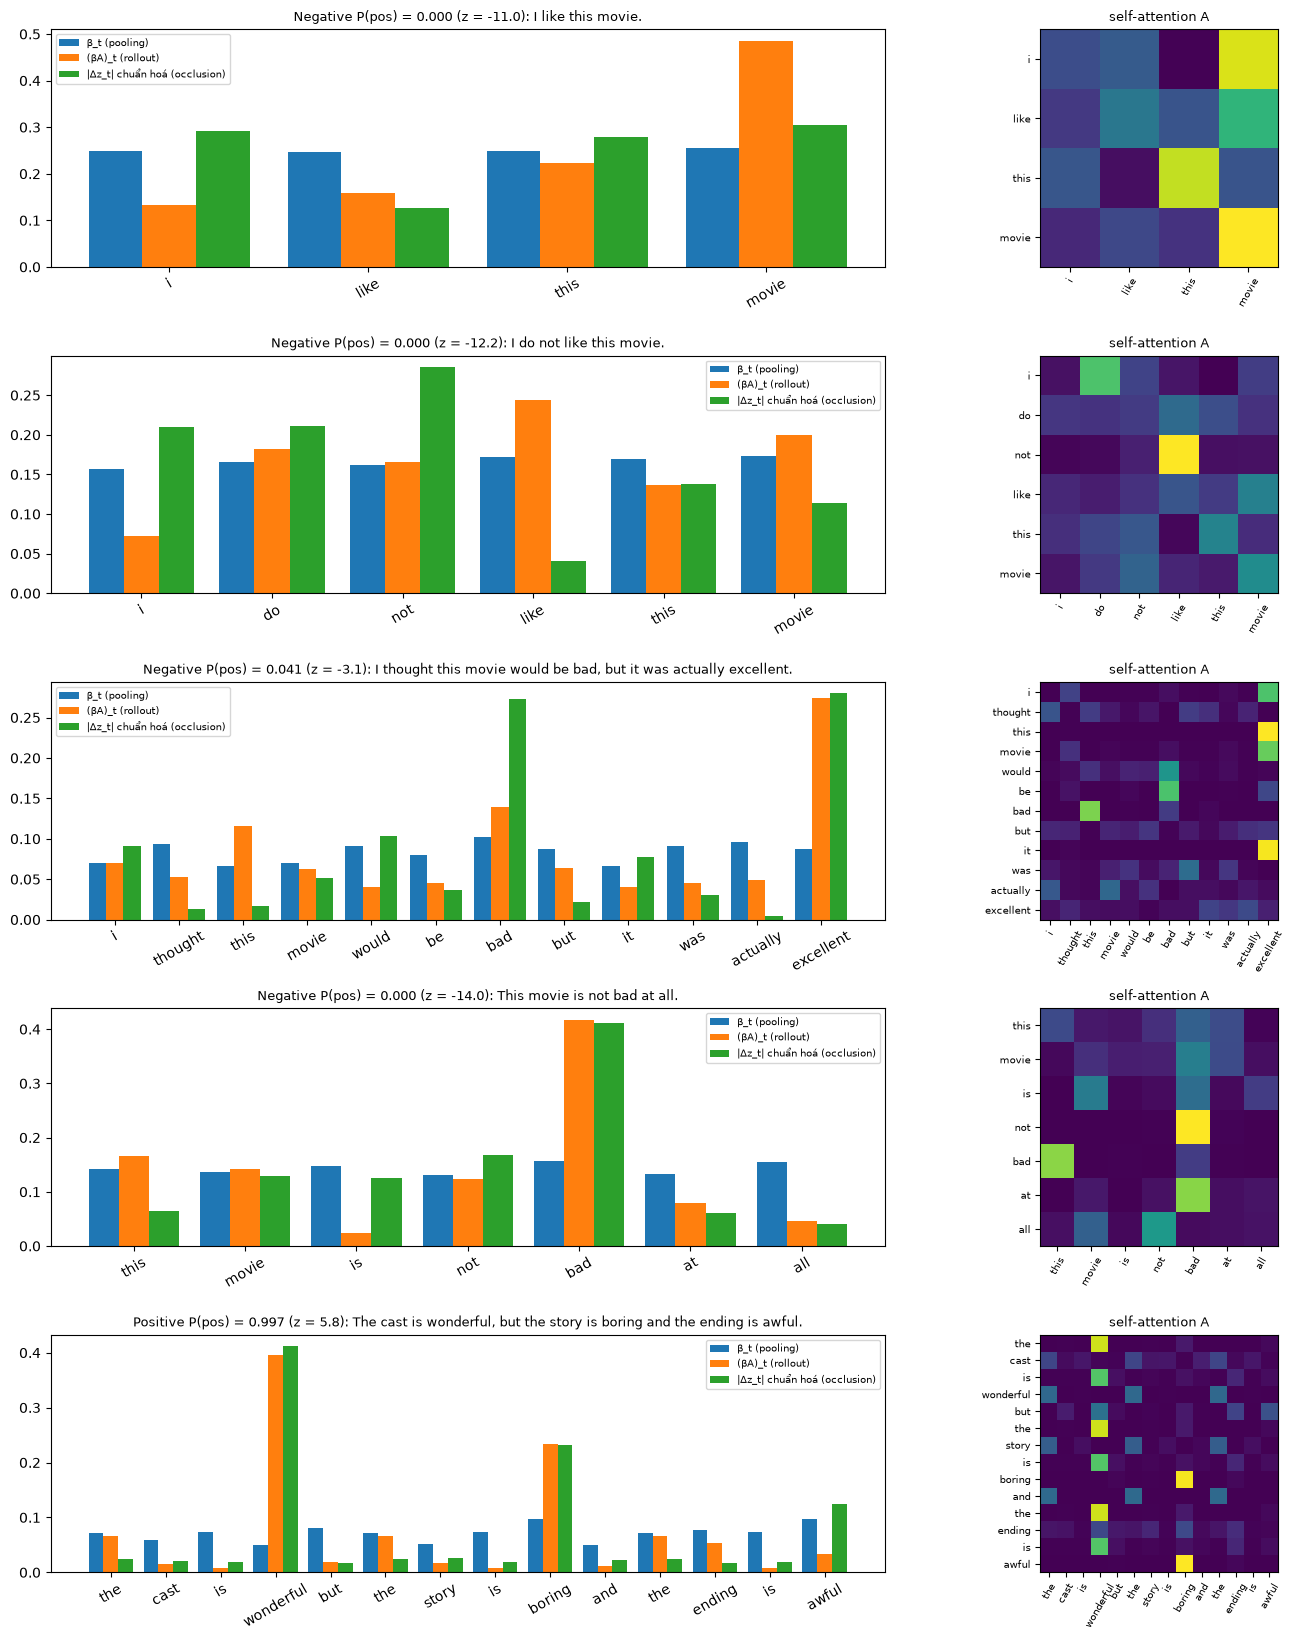

,prediction,P(pos) Self-Attention,logit z,P(pos) LSTM,P(pos) Self-Attention + pos,P(pos) TF-IDF+LR,top β,top βA,top |Δz| (occlusion)
text,,,,,,,,,
I like this movie.,Negative,0.000,-10.953,0.567,0.000,0.300,"movie 0.25, i 0.25, this 0.25","movie 0.49, this 0.22, like 0.16","movie +2.93, i +2.80, this -2.69"
I do not like this movie.,Negative,0.000,-12.243,0.406,0.000,0.049,"movie 0.17, like 0.17, this 0.17","like 0.24, movie 0.20, do 0.18","not -2.89, do +2.13, i +2.13"
"I thought this movie would be bad, but it was actually excellent.",Negative,0.041,-3.145,0.661,0.001,0.551,"bad 0.10, actually 0.10, thought 0.09","excellent 0.27, bad 0.14, this 0.12","excellent +4.22, bad -4.12, would -1.57"
This movie is not bad at all.,Negative,0.000,-13.982,0.149,0.005,0.000,"bad 0.16, all 0.16, is 0.15","bad 0.42, this 0.17, movie 0.14","bad -5.81, not -2.38, movie +1.84"
"The cast is wonderful, but the story is boring and the ending is awful.",Positive,0.997,5.845,0.086,0.315,0.033,"awful 0.10, boring 0.10, but 0.08","wonderful 0.40, boring 0.23, the 0.07","wonderful +15.97, boring -8.99, awful -4.83"


In [26]:
attn_names = ["Self-Attention", "Self-Attention + pos"]
best_attn = max(attn_names, key=lambda n: histories[n].loc[infos[n]["best_epoch"] - 1, "val_f1"])
best_model = models[best_attn]
print("Model attention dùng cho application / error analysis:", best_attn)

def occlusion(model, tokens):
    """Δz_t = z(câu) − z(câu bỏ token t), tính trên logit để không bị bão hoà như P(pos). Δz > 0: token đẩy về positive."""
    ids = encode(tokens)
    variants = [ids] + [ids[:i] + ids[i + 1:] for i in range(len(ids))]
    X, lens = to_tensors(variants)
    z = predict_logit(model, X, lens)
    return z[0], z[0] - z[1:]

def explain(text, model=None, L=MAX_LEN):
    model = model or best_model
    toks = preprocess(text)[:L]
    A, beta, p = model_attention(model, toks)
    z, delta = occlusion(model, toks)
    return {"tokens": toks, "p_pos": p, "z": z, "A": A, "beta": beta, "rollout": beta @ A, "delta": delta}

# Kiểm tra: dự đoán khi pad tới 200 (proba_texts) và khi không pad (model_attention) phải trùng nhau
for n in attn_names:
    diff = max(abs(float(proba_texts(models[n], [t])[0]) - model_attention(models[n], preprocess(t))[2])
               for t in ["I like this movie.", "The cast is wonderful, but the story is boring."])
    print(f"{n}: max |P padded - P không pad| = {diff:.2e}")

APP = ["I like this movie.", "I do not like this movie.",
       "I thought this movie would be bad, but it was actually excellent.",
       "This movie is not bad at all.", "The cast is wonderful, but the story is boring and the ending is awful."]
app_rows = []
fig, axes = plt.subplots(len(APP), 2, figsize=(15, 3.3 * len(APP)), gridspec_kw={"width_ratios": [1.3, 1]})
for r, text in enumerate(APP):
    e = explain(text)
    toks = e["tokens"]
    row = {"text": text, "prediction": "Positive" if e["p_pos"] >= 0.5 else "Negative", f"P(pos) {best_attn}": e["p_pos"],
           "logit z": e["z"]}
    row |= {f"P(pos) {n}": float(proba_texts(m, [text])[0]) for n, m in models.items() if n != best_attn}
    row |= {"P(pos) TF-IDF+LR": float(baseline.predict_proba([text])[0, 1]),
            "top β": ", ".join(f"{toks[i]} {e['beta'][i]:.2f}" for i in np.argsort(-e["beta"])[:3]),
            "top βA": ", ".join(f"{toks[i]} {e['rollout'][i]:.2f}" for i in np.argsort(-e["rollout"])[:3]),
            "top |Δz| (occlusion)": ", ".join(f"{toks[i]} {e['delta'][i]:+.2f}" for i in np.argsort(-np.abs(e["delta"]))[:3])}
    app_rows.append(row)
    log("application", best_attn, text, "-", "p_pos", e["p_pos"])
    ax = axes[r, 0]
    x = np.arange(len(toks))
    ax.bar(x - 0.27, e["beta"], 0.27, label="β_t (pooling)")
    ax.bar(x, e["rollout"], 0.27, label="(βA)_t (rollout)")
    ax.bar(x + 0.27, np.abs(e["delta"]) / max(np.abs(e["delta"]).sum(), 1e-9), 0.27, label="|Δz_t| chuẩn hoá (occlusion)")
    ax.set_xticks(x, toks, rotation=30)
    ax.set_title(f"{row['prediction']} P(pos) = {e['p_pos']:.3f} (z = {e['z']:.1f}): {text}", fontsize=9)
    ax.legend(fontsize=7)
    ax = axes[r, 1]
    ax.imshow(e["A"], cmap="viridis", vmin=0)
    ax.set_xticks(x, toks, rotation=60, fontsize=7)
    ax.set_yticks(x, toks, fontsize=7)
    ax.set_title("self-attention A", fontsize=9)
plt.tight_layout()
plt.savefig("application_attention.png", dpi=110)
plt.show()
pd.DataFrame(app_rows).set_index("text").round(3)

Model: Self-Attention (validation F1 cao hơn).

- **"I like this movie."** → Negative, P = 0.000 (z = −11.0). **Sai**, và sai rất tự tin. LSTM đúng (0.567). βA tập trung vào movie 0.49, this 0.22, like chỉ 0.16. Giả thuyết: model chưa từng thấy input 4 token (chỉ 2.4% review train dài ≤ 50 token). Với ít token, context gần như chỉ là value của một hai token, và "this movie" rất thường gặp trong review chê ở IMDb (TF-IDF cũng chỉ cho 0.300). Đây là domain shift về độ dài, không phải do attention "nhìn sai".
- **"I do not like this movie."** → Negative, P = 0.000. **Đúng nhãn**, nhưng occlusion cho thấy token quyết định là "not" (Δz = −2.89), tức "not" đóng vai một từ tiêu cực độc lập. Model này không có vị trí nên "movie this like not do I" cũng cho cùng kết quả. Hàng "not" trong heatmap chú ý gần hết vào "like", trông như phủ định đúng chỗ, nhưng đó là quan hệ giữa hai từ (not, like), không phải phạm vi phủ định theo thứ tự.
- **"I thought this movie would be bad, but it was actually excellent."** → Negative, P = 0.041. **Sai** (LSTM đúng 0.661). excellent (+4.22) và bad (−4.12) gần như triệt tiêu nhau. Model không biết "but" và vị trí đảo ngược ý: đổi chỗ bad với excellent cho **cùng** prediction, vì đây là cùng một bag-of-words.
- **"This movie is not bad at all."** → Negative, P = 0.000. Sai: bad (−5.81) lấn át, "not" còn đẩy thêm về negative (−2.38).
- **"The cast is wonderful, but the story is boring and the ending is awful."** → Positive, P = 0.997. **Sai** (LSTM đúng 0.086). wonderful có Δz = +15.97, lớn hơn boring (−8.99) và awful (−4.83) cộng lại. Heatmap: nhiều hàng (the, is, cast) cùng chú ý vào "wonderful", nên value của nó bị chép vào nhiều vị trí; vì β gần đều, số hàng chứa "wonderful" quyết định context.

βA (rollout) khớp với occlusion ở các câu này (wonderful, excellent / bad, bad), còn β gần đều nên không nói được gì. Attention chỉ ra **model dựa vào token nào**, không giải thích **vì sao** model kết luận sai.

## 11. Error analysis

### 11.1 Attention có trùng với token quan trọng theo occlusion không?

300 review test ngẫu nhiên dài ≤ 200 token (không bị truncate). Với mỗi review so sánh ba thứ hạng token: β_t (pooling weight), (βA)_t (attention rollout về token input) và |Δz_t| (occlusion trên logit, thay đổi thật của prediction khi bỏ token). Thêm deletion test: bỏ 3 token có β / βA / |Δz| cao nhất hoặc 3 token ngẫu nhiên, rồi đo |z mới − z cũ|. Kèm theo entropy chuẩn hoá H/ln n của β và của từng hàng A (1 = đều, 0 = dồn vào một token).

In [27]:
rng_e = np.random.default_rng(SEED)
cand = np.where((len_test >= 10) & (len_test <= MAX_LEN))[0]
sample_idx = rng_e.choice(cand, size=min(100 if QUICK else 300, len(cand)), replace=False)
faith_rows = []
for i in sample_idx:
    toks = tok_test[i]
    e = explain(" ".join(toks))
    ad = np.abs(e["delta"])
    ids = encode(toks)
    def drop_z(pos):
        keep = [x for j, x in enumerate(ids) if j not in set(pos)]
        X1, L1 = to_tensors([keep])
        return abs(float(predict_logit(best_model, X1, L1)[0]) - e["z"])
    n = len(toks)
    faith_rows.append({
        "idx": i, "n": n,
        "H(β)/ln n": entropy(e["beta"]) / np.log(n),
        "H(A_i)/ln n (trung bình hàng)": entropy(e["A"]).mean() / np.log(n),
        "max A_i (trung bình hàng)": e["A"].max(1).mean(),
        "spearman β vs |Δz|": spearmanr(e["beta"], ad).statistic,
        "spearman βA vs |Δz|": spearmanr(e["rollout"], ad).statistic,
        "top1 β = top1 |Δz|": int(np.argmax(e["beta"]) == np.argmax(ad)),
        "top1 βA = top1 |Δz|": int(np.argmax(e["rollout"]) == np.argmax(ad)),
        "|Δz| bỏ top-3 β": drop_z(np.argsort(-e["beta"])[:3]),
        "|Δz| bỏ top-3 βA": drop_z(np.argsort(-e["rollout"])[:3]),
        "|Δz| bỏ 3 ngẫu nhiên": drop_z(rng_e.choice(n, 3, replace=False)),
        "|Δz| bỏ top-3 |Δz|": drop_z(np.argsort(-ad)[:3]),
    })
faith = pd.DataFrame(faith_rows)
faith_summary = faith.drop(columns=["idx", "n"]).mean()
for k, v in faith_summary.items():
    log("faithfulness", best_attn, "300 reviews", "test", k, v)
faith_summary.round(4)

H(β)/ln n                        0.9967
H(A_i)/ln n (trung bình hàng)    0.7137
max A_i (trung bình hàng)        0.1735
spearman β vs |Δz|              -0.0285
spearman βA vs |Δz|              0.3538
top1 β = top1 |Δz|               0.1167
top1 βA = top1 |Δz|              0.5267
|Δz| bỏ top-3 β                  1.2368
|Δz| bỏ top-3 βA                 1.2887
|Δz| bỏ 3 ngẫu nhiên             0.2489
|Δz| bỏ top-3 |Δz|               1.2535
dtype: float64

### 11.2 Review đúng / sai

Ưu tiên review ngắn (15 - 120 token) để đọc được. Với mỗi review: top token theo β và theo occlusion.

In [28]:
ea = test_df.assign(n_tokens=len_test, p_pos=test_proba[best_attn], pred=preds[best_attn],
                    p_lstm=test_proba["LSTM"], p_base=p_base)
for n in attn_names:
    ea[f"p_{n}"] = test_proba[n]
ea["correct"] = ea["pred"] == ea["label"]
ea["conf"] = (ea["p_pos"] - 0.5).abs()
print("Tỉ lệ lỗi:", f"{100 * (~ea.correct).mean():.1f}%", "| truncate:",
      f"{100 * (~ea.correct[ea.n_tokens > MAX_LEN]).mean():.1f}%", "| không truncate:",
      f"{100 * (~ea.correct[ea.n_tokens <= MAX_LEN]).mean():.1f}%")
both = pd.crosstab(ea["correct"].map({True: f"{best_attn} đúng", False: f"{best_attn} sai"}),
                   (preds["LSTM"] == ea["label"]).map({True: "LSTM đúng", False: "LSTM sai"}))
display(both)
short = ea[ea["n_tokens"].between(15, 120)]
cases = pd.concat([short[short.correct & (short.label == 1)].nlargest(3, "conf"),
                   short[short.correct & (short.label == 0)].nlargest(3, "conf"),
                   short[~short.correct & (short.label == 0)].nlargest(5, "conf"),
                   short[~short.correct & (short.label == 1)].nlargest(5, "conf")])
cols = ["text", "label", "pred", "p_pos", "p_lstm", "p_base"] + [f"p_{n}" for n in attn_names]
display(cases[cols].round(3))

Tỉ lệ lỗi: 16.3% | truncate: 19.9% | không truncate: 13.9%


label,LSTM sai,LSTM đúng
correct,,
Self-Attention sai,2468,1565
Self-Attention đúng,1861,18784


,text,label,pred,p_pos,p_lstm,p_base,p_Self-Attention,p_Self-Attention + pos
18286,Rating-10 Classic Waters! One of his best and most shocking films! Divine is THE most filthy person ever! Mink Stole also delivers a superb performance!,1,1,1.000,0.977,0.990,1.000,1.000
13867,"Morte a Venezia is one of my favorite movies. More than beautiful, it's really sublime. It gives you important aesthetic experiences, it's a masterpiece. I also recommend the novel. Luchino Viscon...",1,1,1.000,0.958,0.991,1.000,1.000
14683,I found this movie to be a simple yet wonderful comedy. This movie is purely entertaining. I can watch it time and time again and still enjoy the dialog and chemistry between the characters. I tru...,1,1,1.000,0.987,0.999,1.000,1.000
10512,"Sure it is a new take on vampires. Who cares. I would rather the old take if it is entertaining. This was not entertaining. It was a dull story, poorly acted, with annoying cinematography. Save yo...",0,0,0.000,0.009,0.002,0.000,0.000
11465,"At least the jingle by Tim Finn was melodic. Roberts is the his usual inept self. Characters are inconsistent, dull, purposeless. Roberts changes his accent even within one line.",0,0,0.000,0.046,0.030,0.000,0.000
3874,"This is a terrible movie, don't waste your money on it. Don't even watch it for free. That's all I have to say.",0,0,0.000,0.093,0.000,0.000,0.000
3469,"This film has the language, the style and the attitude down ... plus greats rides from Occy (a world champ) and the great Jerry Lopez. John Philbin as Turtle has the surf pidgin down, and the surf...",0,1,1.000,0.929,0.991,1.000,1.000
11859,"This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although ...",0,1,1.000,0.990,0.996,1.000,1.000
4020,This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in ...,0,1,1.000,0.953,0.995,1.000,1.000
5227,"I enjoyed the beautiful scenery in this movie the first time I saw it when I was 9 . Dunderklumpen is kind of cute for kiddies in a corny way. It reminded me of HRPUFFINSTUFF on sat mornings, Its ...",0,1,1.000,0.909,0.991,1.000,1.000


In [29]:
for i, r in cases.iterrows():
    e = explain(r.text)
    toks = e["tokens"]
    tb = ", ".join(f"{toks[j]}@{j} {e['beta'][j]:.2f}" for j in np.argsort(-e["beta"])[:5])
    tr = ", ".join(f"{toks[j]}@{j} {e['rollout'][j]:.2f}" for j in np.argsort(-e["rollout"])[:5])
    td = ", ".join(f"{toks[j]}@{j} {e['delta'][j]:+.2f}" for j in np.argsort(-np.abs(e["delta"]))[:5])
    print(f"#{i} true={LABEL_NAMES[r.label]} pred={LABEL_NAMES[r.pred]} P(pos)={e['p_pos']:.3f} z={e['z']:.1f} n={len(toks)}\n"
          f"   β: {tb}\n   βA: {tr}\n   Δz: {td}")

#18286 true=positive pred=positive P(pos)=1.000 z=14.0 n=26
   β: person@17 0.04, stole@20 0.04, waters@3 0.04, of@5 0.04, the@14 0.04
   βA: is@13 0.18, the@14 0.16, best@7 0.05, one@4 0.05, most@15 0.05
   Δz: is@13 +1.16, best@7 +0.99, person@17 -0.73, one@4 -0.72, divine@12 +0.64
#13867 true=positive pred=positive P(pos)=1.000 z=12.9 n=34
   β: novel@28 0.04, it's@12 0.03, it's@21 0.03, is@3 0.03, is@31 0.03
   βA: the@27 0.10, is@3 0.10, is@31 0.10, beautiful@11 0.08, it's@12 0.07
   Δz: beautiful@11 +1.83, novel@28 -1.47, favorite@7 +0.75, aesthetic@19 +0.60, visconti@30 +0.53
#14683 true=positive pred=positive P(pos)=1.000 z=12.1 n=41
   β: purely@14 0.04, between@31 0.03, characters@33 0.03, dialog@28 0.03, is@13 0.03
   βA: wonderful@9 0.32, is@13 0.10, the@27 0.06, the@32 0.06, purely@14 0.04
   Δz: wonderful@9 +5.62, purely@14 -2.55, between@31 -0.65, enjoy@26 +0.63, characters@33 -0.48
#10512 true=negative pred=negative P(pos)=0.000 z=-14.4 n=43
   β: dull@27 0.03, annoying

#11859 true=negative pred=positive P(pos)=1.000 z=8.5 n=81
   β: actor@60 0.02, am@14 0.02, such@52 0.02, few@31 0.01, 20@24 0.01
   βA: great@37 0.08, the@34 0.06, favorite@71 0.06, hilarious@11 0.04, brilliant@8 0.03
   Δz: hilarious@11 +0.81, actor@60 -0.68, beautiful@54 +0.52, favorite@71 +0.52, been@43 -0.45
#4020 true=negative pred=positive P(pos)=1.000 z=8.5 n=61
   β: actor@47 0.02, deputy@54 0.02, fight@50 0.02, final@49 0.02, case@26 0.02
   βA: great@46 0.14, kung@7 0.05, definitely@2 0.04, best@6 0.03, well@19 0.03
   Δz: great@46 +1.17, kung@7 +1.00, actor@47 -0.98, best@6 +0.70, deputy@54 -0.69
#5227 true=negative pred=positive P(pos)=1.000 z=7.6 n=95
   β: 1974@94 0.01, bored@69 0.01, kiddies@24 0.01, were@90 0.01, don't@46 0.01
   βA: enjoyed@1 0.10, bit@82 0.03, is@58 0.03, is@19 0.03, is@71 0.03
   Δz: enjoyed@1 +1.01, easy@42 +0.66, sat@35 -0.59, beautiful@3 +0.59, 1974@94 -0.47
#250 true=negative pred=positive P(pos)=0.999 z=7.5 n=91
   β: 3@25 0.02, unbearable@18 0

#12735 true=positive pred=negative P(pos)=0.004 z=-5.6 n=55
   β: plot@23 0.02, writing@27 0.02, unfortunately@20 0.02, hoping@35 0.02, i'm@34 0.02
   βA: this@18 0.10, unfortunately@20 0.09, poor@26 0.05, braugher@4 0.04, overhaul@42 0.04
   Δz: unfortunately@20 -1.52, andre@3 +0.79, this@18 -0.66, plot@23 -0.61, poor@26 -0.55
#16917 true=positive pred=negative P(pos)=0.004 z=-5.6 n=98
   β: decent@61 0.01, actor@51 0.01, horrible@94 0.01, sucks@29 0.01, bad@82 0.01
   βA: horrible@94 0.07, bad@82 0.07, bad@93 0.07, sucks@29 0.06, fun@85 0.04
   Δz: sucks@29 -1.36, horrible@94 -1.27, fun@85 +1.02, 7@96 +0.69, definitely@90 +0.63
#18672 true=positive pred=negative P(pos)=0.005 z=-5.4 n=35
   β: money@4 0.04, only@20 0.04, 86@28 0.03, mention@23 0.03, fails@7 0.03
   βA: fails@7 0.16, mid@14 0.12, it's@30 0.06, also@29 0.04, the@13 0.04
   Δz: fails@7 -3.59, mid@14 +1.58, money@4 -1.44, also@29 +0.94, the@13 +0.86
#18661 true=positive pred=negative P(pos)=0.007 z=-5.0 n=99
   β: weak@90

**Attention có trùng với token quan trọng không? (300 review)**

| Chỉ số | Giá trị |
|---|---|
| H(β) / ln n | 0.997: β gần như đều, pooling ≈ mean pooling |
| H(A_i) / ln n trung bình | 0.714: từng hàng của A tập trung hơn nhiều |
| Spearman(β, \|Δz\|) | −0.03 |
| Spearman(βA, \|Δz\|) | 0.35 |
| Top-1 trùng occlusion: β / βA | 11.7% / 52.7% |
| \|Δz\| khi bỏ 3 token: top β / top βA / top \|Δz\| / ngẫu nhiên | 1.24 / 1.29 / 1.25 / 0.25 |

- Pooling weight β nhìn gần như đều nên đọc trên hình không thấy gì. Tuy vậy, bỏ 3 token có β cao nhất vẫn làm logit đổi gấp 5 lần bỏ 3 token ngẫu nhiên: chênh lệch nhỏ của β vẫn mang tín hiệu.
- Attention rollout βA gần với occlusion hơn hẳn (top-1 trùng khoảng một nửa số review), nhưng vẫn chỉ tương quan vừa phải (0.35).
- Vậy câu hỏi "attention có nhìn đúng token không" phụ thuộc vào việc nhìn attention nào (β hay A hay βA), và kết luận phải được đối chiếu với hành vi thật của model (occlusion, deletion), không suy ra từ heatmap.

**Các review cụ thể:** chi tiết ở `error_analysis.md`. Tỉ lệ lỗi của Self-Attention là 16.3%: 19.9% trên review bị truncate, 13.9% trên review không bị truncate. Các nhóm lỗi chính: domain shift (câu ngắn), không có thứ tự nên không xử lý được contrast và negation, một từ cảm xúc mạnh lấn át cả câu, rare word, và nhãn nhiễu.

## 12. Lưu kết quả

In [30]:
if not QUICK:
    pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
print(len(RESULTS), "dòng" + ("" if QUICK else " đã ghi vào results.csv"))

729

 dòng đã ghi vào results.csv
